In [1]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
    font-family: 'Segoe UI', Roboto, Arial, sans-serif;
    background: linear-gradient(135deg, #1c5cab 0%, #2a78d6 60%, #5598e7 100%);
    color: #ffffff;
    padding: 28px 32px;
    border-radius: 14px;
    margin: 8px 0 16px 0;
    box-shadow: 0 4px 14px rgba(0,0,0,0.15);
">
  <div style="font-size: 13px; letter-spacing: 2px; text-transform: uppercase; opacity: 0.85;">
    Proyecto de Inteligencia Artificial
  </div>
  <div style="font-size: 30px; font-weight: 700; margin: 6px 0 4px 0;">
    Breast Cancer Wisconsin (Diagnostic)
  </div>
  <div style="font-size: 16px; opacity: 0.9; margin-bottom: 18px;">
    Análisis exploratorio y clasificación de tumores: maligno (M) vs. benigno (B)
  </div>

  <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 18px;">
    <ul>
    <li>Juan Camilo Arias Sarabia</li>
    <li>David Ricardo Martinez </li>
    <li>Juan Felipe Castellanos</li>
    </ul>
  </div>
  <div style="display: flex; gap: 12px; flex-wrap: wrap; margin-bottom: 18px;">
    <span style="background: rgba(255,255,255,0.18); padding: 6px 12px; border-radius: 20px; font-size: 14px;">569 registros</span>
    <span style="background: rgba(255,255,255,0.18); padding: 6px 12px; border-radius: 20px; font-size: 14px;">30 variables numéricas</span>
    <span style="background: rgba(255,255,255,0.18); padding: 6px 12px; border-radius: 20px; font-size: 14px;">Clasificación binaria</span>
  </div>

  <div style="font-size: 14px;">
    Fuente:
    <a href="https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data"
       target="_blank"
       style="color: #ffffff; font-weight: 600; text-decoration: underline;">
       kaggle.com/datasets/uciml/breast-cancer-wisconsin-data
    </a>
  </div>
</div>
"""))

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import os

# Usa el CSV del repositorio (data/data.csv); si no existe, monta Google Drive (Colab)
RUTA = 'data'
if not os.path.exists(f'{RUTA}/data.csv'):
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA = '/content/drive/MyDrive/IA_2026-2'

In [4]:
df = pd.read_csv(f'{RUTA}/data.csv')

#Exploración inicial

In [5]:
df.head(-1)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,29.41,179.10,1819.0,0.1407,0.4186,0.6599,0.2542,0.2929,0.09873,NaN
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.1410,0.2113,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.1166,0.1922,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.1139,0.3094,0.3403,0.1418,0.2218,0.07820,NaN


In [6]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [ ]:
df.shape

(569, 33)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


#Limpieza Inicial

In [9]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [10]:
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

In [11]:
df.isna().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [12]:
df.duplicated().sum()

np.int64(0)

#Cuartiles y rango intercuartílico

In [13]:
num= df.select_dtypes(include="number")
Q1= num.quantile(0.25)
Q3= num.quantile(0.75)
IQR=Q3-Q1
limite_inferior= Q1-1.5*IQR
limite_superior=Q3 +1.5*IQR

atipicos = (num < limite_inferior) | (num > limite_superior)
resumen= pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "limite_inferior": limite_inferior,
    "limite_superior": limite_superior,
    "n_atipicos": atipicos.sum()
}
)
resumen.sort_values("n_atipicos", ascending=False)



,Q1,Q3,IQR,limite_inferior,limite_superior,n_atipicos
area_se,17.850000,45.190000,27.340000,-23.160000,86.200000,65
radius_se,0.232400,0.478900,0.246500,-0.137350,0.848650,38
perimeter_se,1.606000,3.357000,1.751000,-1.020500,5.983500,38
area_worst,515.300000,1084.000000,568.700000,-337.750000,1937.050000,35
smoothness_se,0.005169,0.008146,0.002977,0.000703,0.012612,30
fractal_dimension_se,0.002248,0.004558,0.002310,-0.001217,0.008023,28
compactness_se,0.013080,0.032450,0.019370,-0.015975,0.061505,28
symmetry_se,0.015160,0.023480,0.008320,0.002680,0.035960,27
area_mean,420.300000,782.700000,362.400000,-123.300000,1326.300000,25
fractal_dimension_worst,0.071460,0.092080,0.020620,0.040530,0.123010,24


In [14]:
pd.DataFrame({c: df.loc[atipicos[c], "diagnosis"].value_counts()
              for c in atipicos.columns}).T.fillna(0).astype(int)

diagnosis,B,M
radius_mean,0,14
texture_mean,2,5
perimeter_mean,0,13
area_mean,0,25
smoothness_mean,3,3
compactness_mean,0,16
concavity_mean,3,15
concave points_mean,0,10
symmetry_mean,6,9
fractal_dimension_mean,10,5


#GRAFICOS

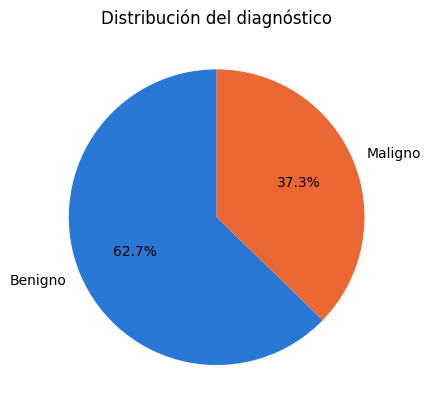

In [15]:
colores = {"B": "#2a78d6", "M": "#eb6834"}
etiquetas = {"B": "Benigno", "M": "Maligno"}
cols_mean = [c for c in df.columns if c.endswith("_mean")]

conteo = df["diagnosis"].value_counts()
plt.pie(conteo, labels=[etiquetas[k] for k in conteo.index],
        colors=[colores[k] for k in conteo.index], autopct="%1.1f%%", startangle=90)
plt.title("Distribución del diagnóstico")
plt.show()

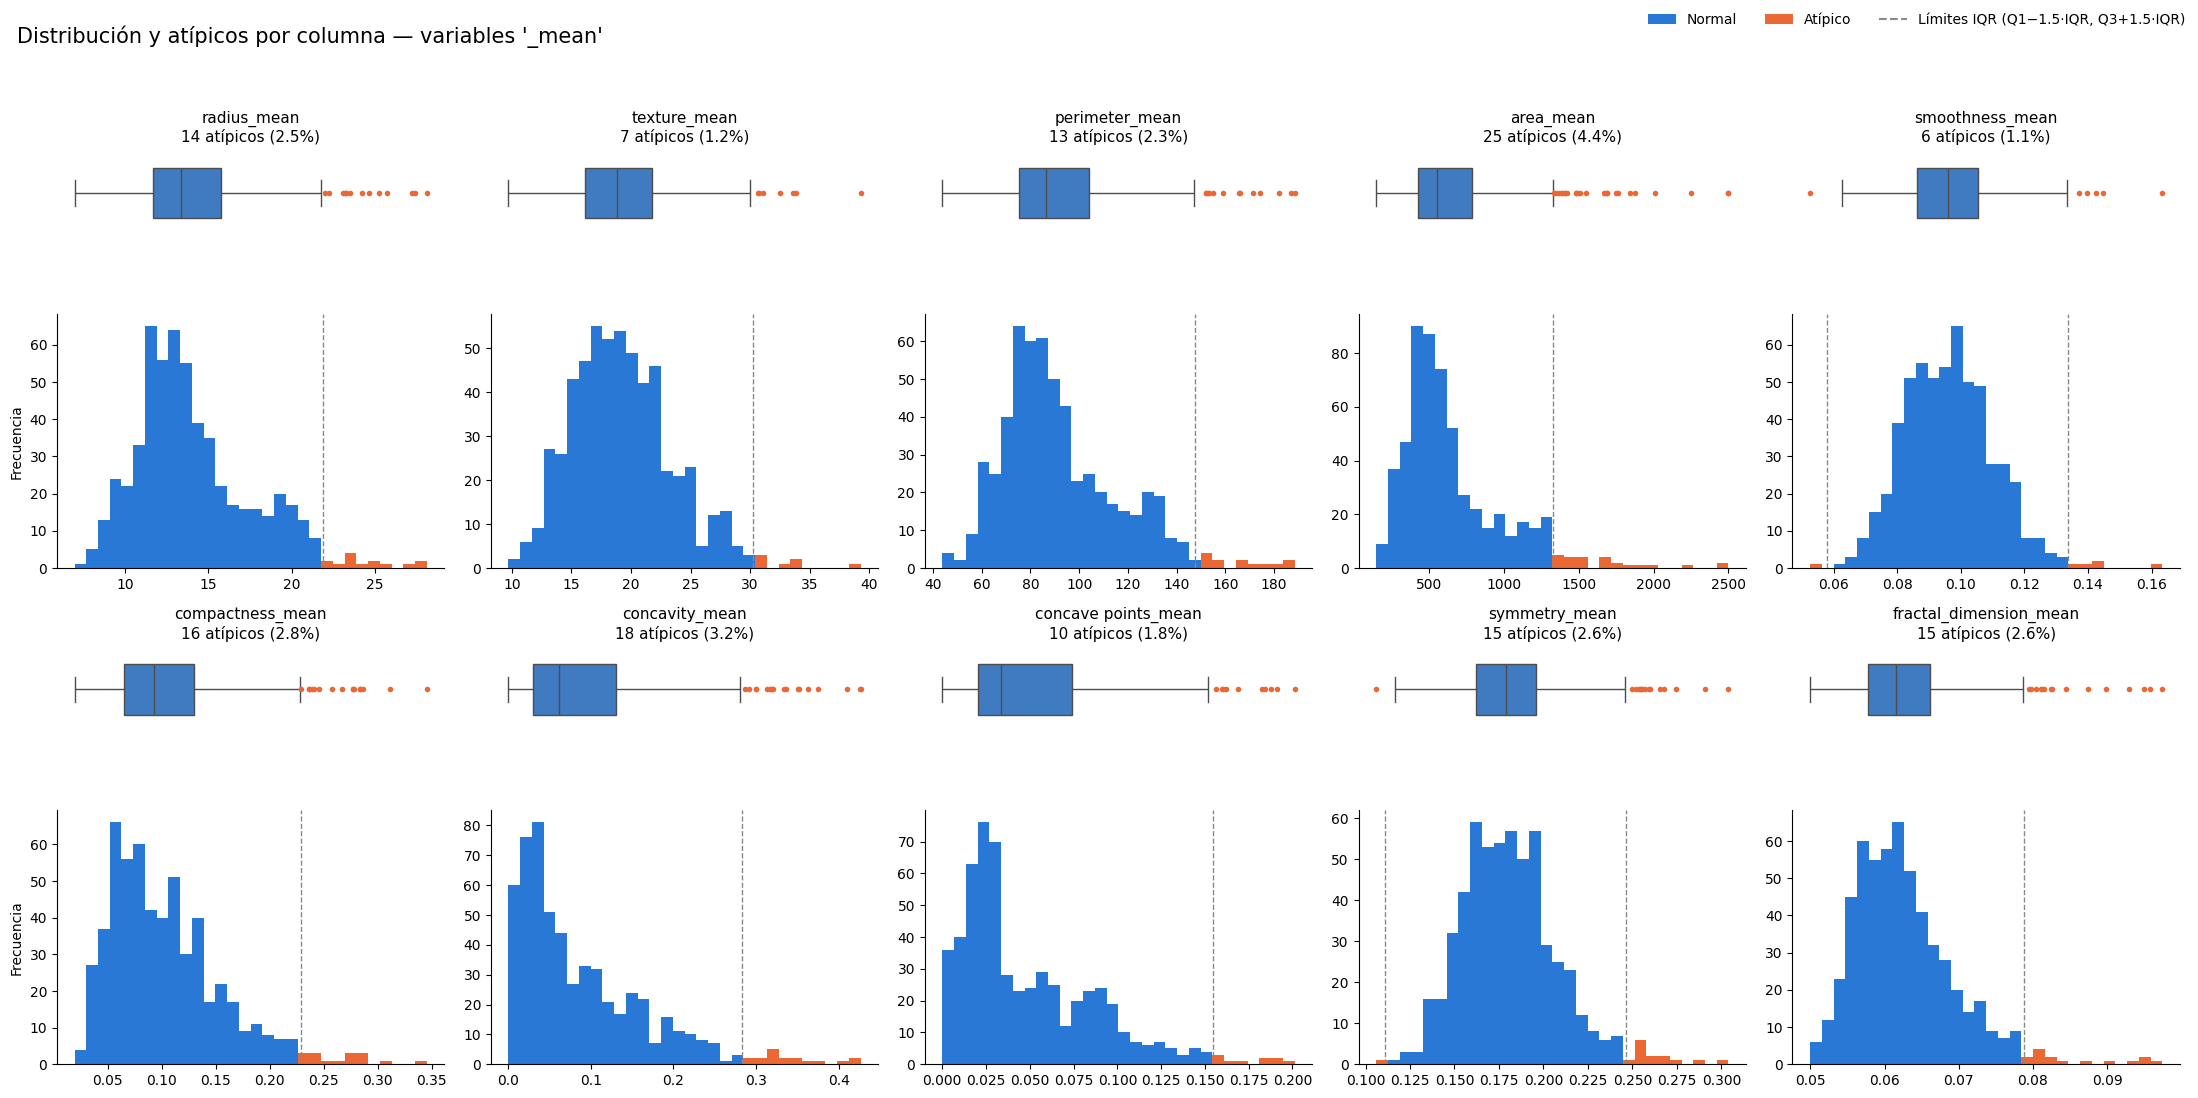

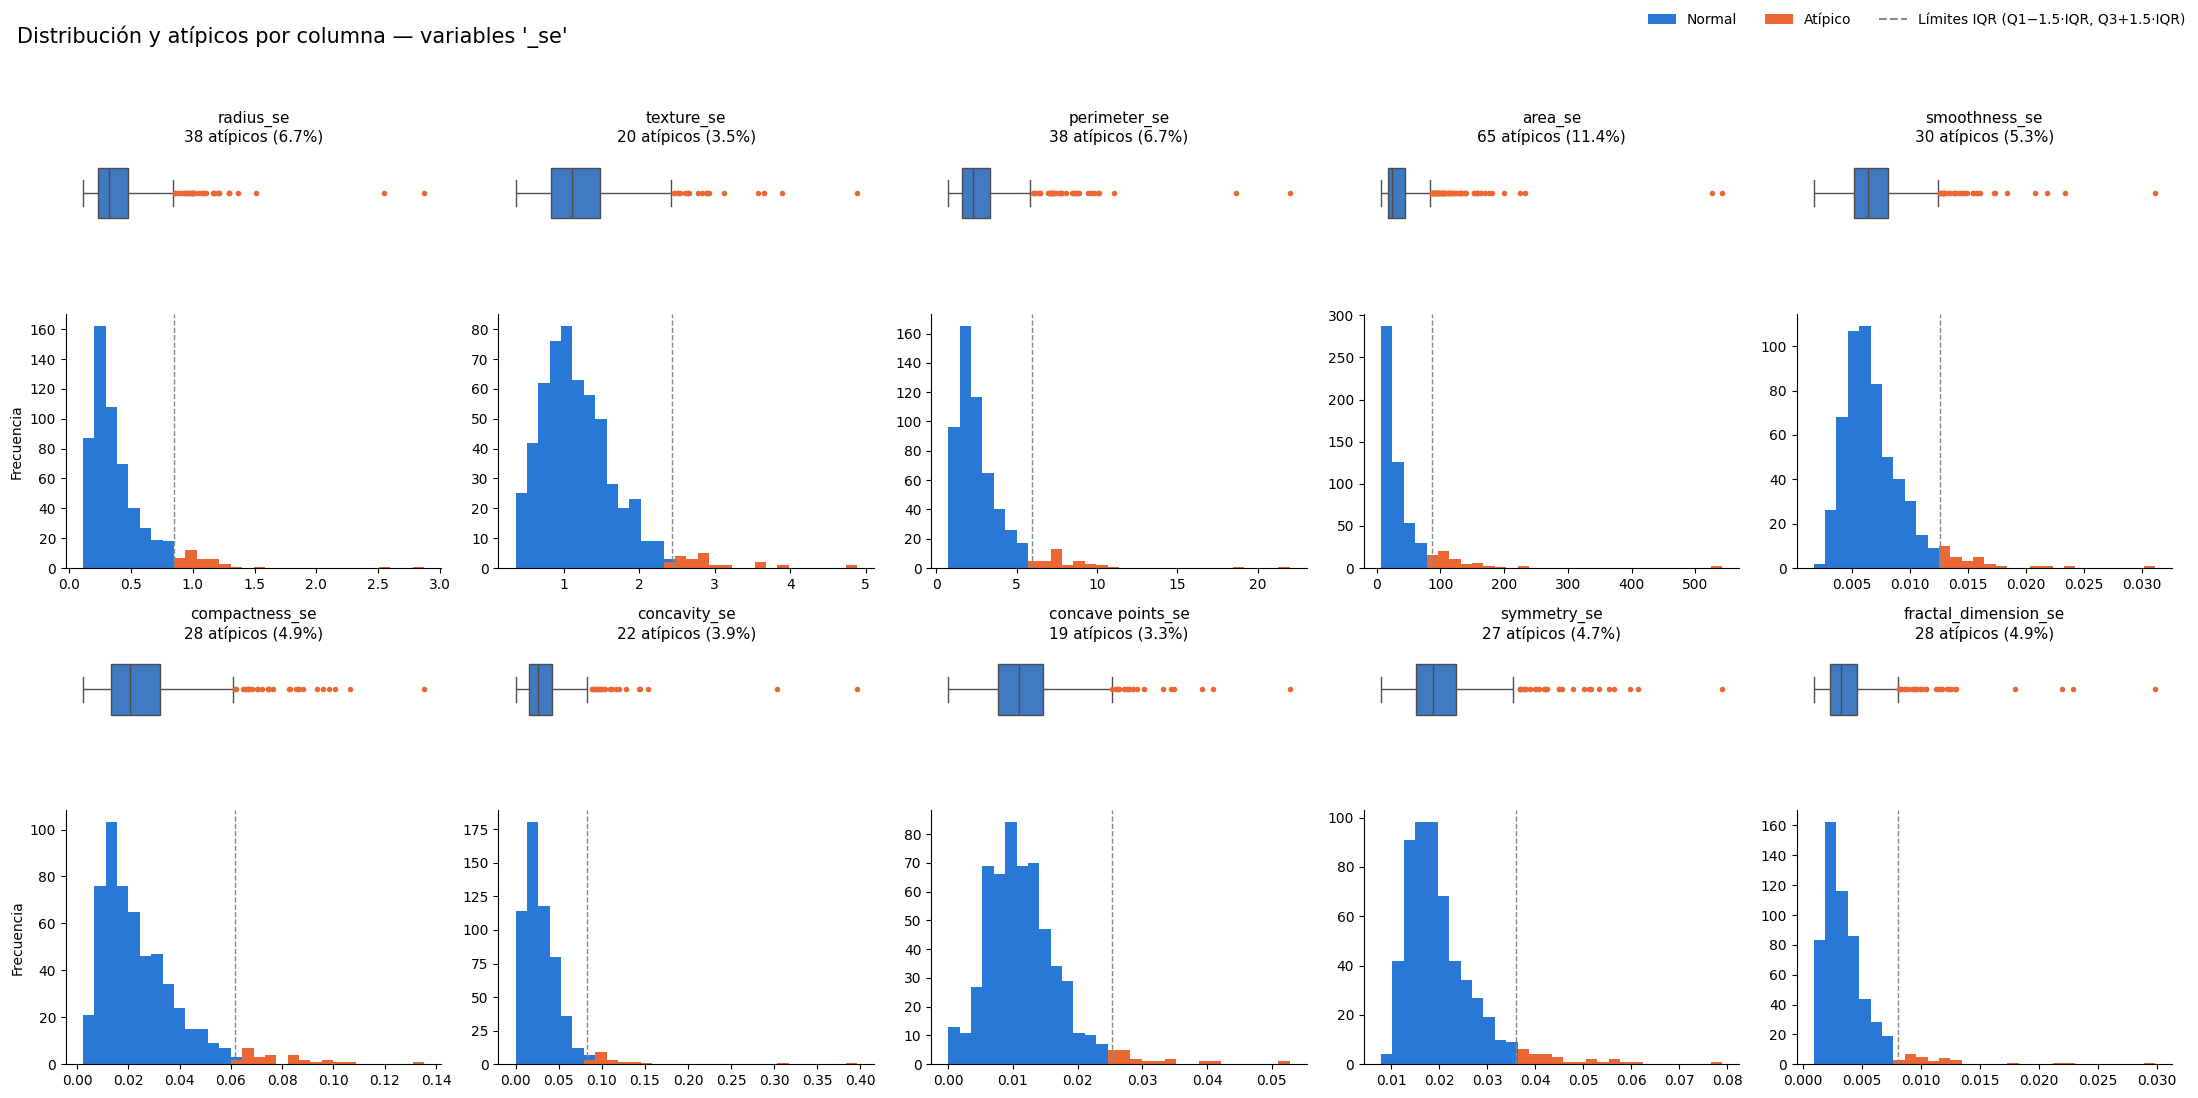

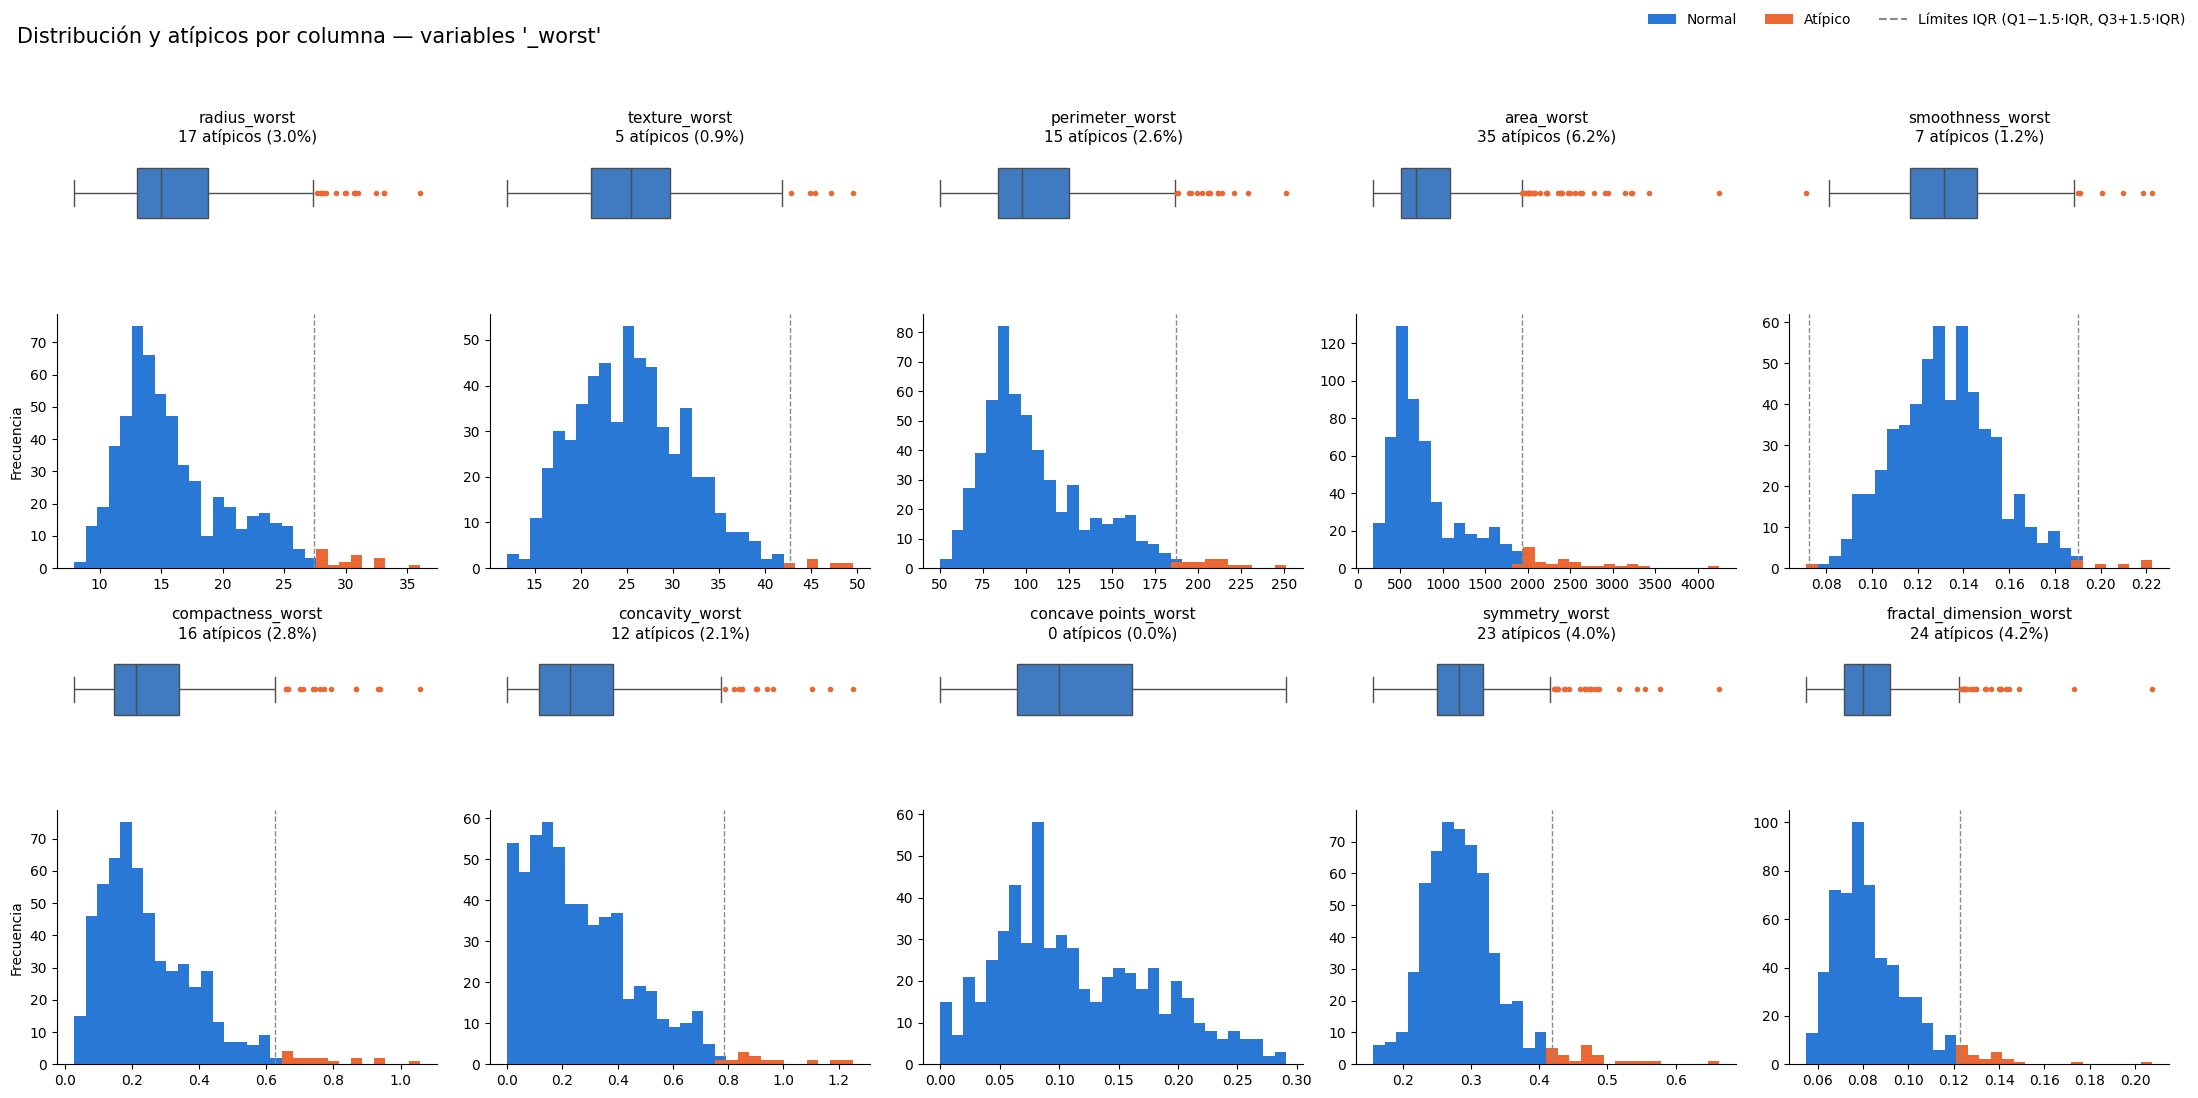

In [16]:

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"

def graficar_grupo(df, sufijo, archivo=None):
    cols = [c for c in df.columns if c.endswith(sufijo)]
    fig, axes = plt.subplots(4, 5, figsize=(22, 11),
                             gridspec_kw={"height_ratios": [1, 3, 1, 3]})
    for i, c in enumerate(cols):
        fila, col = divmod(i, 5)
        ax_box, ax_hist = axes[fila * 2, col], axes[fila * 2 + 1, col]
        x = df[c]

        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        atip = (x < li) | (x > ls)

        # Boxplot arriba
        sns.boxplot(x=x, ax=ax_box, color=AZUL, width=0.6, linewidth=1,
                    flierprops=dict(marker="o", markersize=4,
                                    markerfacecolor=NARANJA, markeredgecolor="none"))
        ax_box.set(xlabel="", yticks=[])
        ax_box.tick_params(axis="x", labelbottom=False, length=0)
        ax_box.set_title(f"{c}\n{atip.sum()} atípicos ({atip.mean():.1%})", fontsize=11)
        for s in ["top", "right", "left", "bottom"]:
            ax_box.spines[s].set_visible(False)

        # Histograma abajo: normales en azul, atípicos en naranja
        bins = 30
        rango = (x.min(), x.max())
        ax_hist.hist(x[~atip], bins=bins, range=rango, color=AZUL, label="Normal")
        ax_hist.hist(x[atip], bins=bins, range=rango, color=NARANJA, label="Atípico")
        for lim in (li, ls):
            if rango[0] <= lim <= rango[1]:
                ax_hist.axvline(lim, color=GRIS, ls="--", lw=1)
        ax_hist.set(xlabel="", ylabel="Frecuencia" if col == 0 else "")
        ax_box.sharex(ax_hist)
        for s in ["top", "right"]:
            ax_hist.spines[s].set_visible(False)

    handles, labels = axes[1, 0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], color=GRIS, ls="--"))
    labels.append("Límites IQR (Q1−1.5·IQR, Q3+1.5·IQR)")
    fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False)
    fig.suptitle(f"Distribución y atípicos por columna — variables '{sufijo}'",
                 fontsize=15, x=0.01, ha="left")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    if archivo:
        plt.savefig(archivo, dpi=110)
    plt.show()

for sufijo in ["_mean", "_se", "_worst"]:
    graficar_grupo(df, sufijo, archivo=f"atipicos{sufijo}.png")

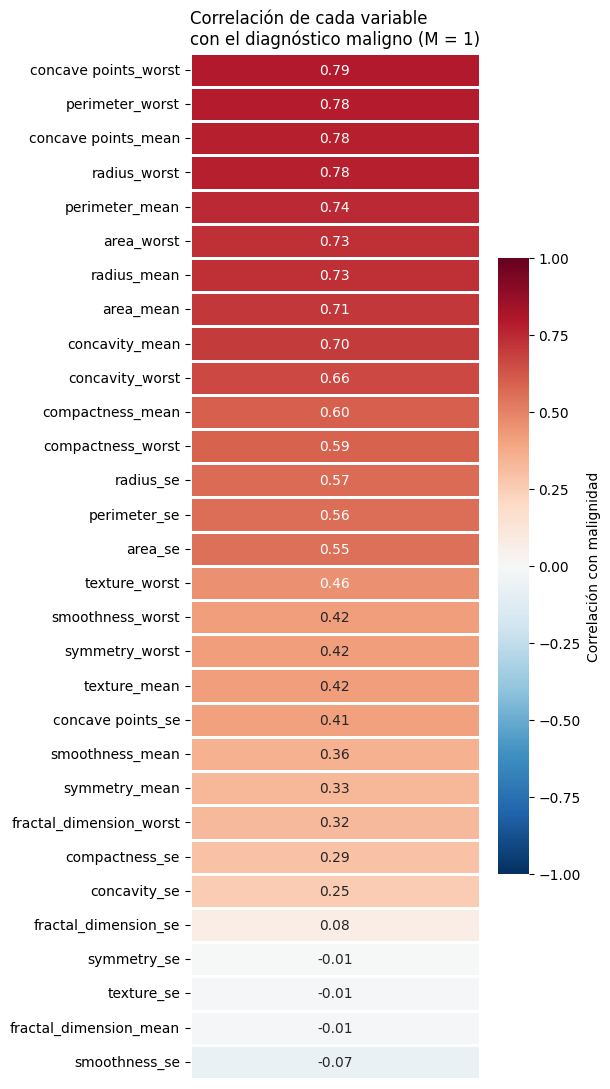

In [17]:
target = df["diagnosis"].map({"M": 1, "B": 0})

corr_target = (df.drop(columns="diagnosis")
                 .corrwith(target)
                 .sort_values(ascending=False)
                 .to_frame("Correlación"))

plt.figure(figsize=(6, 11))
sns.heatmap(corr_target, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=1, linecolor="white",
            cbar_kws={"label": "Correlación con malignidad", "shrink": 0.6})
plt.title("Correlación de cada variable\ncon el diagnóstico maligno (M = 1)", loc="left")
plt.xticks([])
plt.ylabel("")
plt.tight_layout()
plt.show()

#CLASIFICACION
La variable objetivo es categórica. diagnosis solo toma dos valores, M (maligno) o B (benigno). El objetivo seria predecir una categoría.

Cada uno de los 569 registros ya tiene su diagnóstico conocido. Con esas etiquetas el modelo aprende a asignar cada nuevo tumor a una de las dos clases.

No es posible hacer Regresión pues la regresión predice un valor numérico continuo. En este dataset lo que interesa predecir es el diagnóstico, que es una categoría. Las 30 variables numéricas son predictoras: describen la forma del núcleo, no son el resultado que se busca.

# SEGUNDA ETAPA: MODELADO

En esta etapa se entrenan y comparan cuatro clasificadores para predecir `diagnosis` (M = 1, B = 0):

1. Limpieza del dataset
2. Particionado 80/20
3. Estimadores: Decision Tree (`max_depth`), Random Forest (`n_estimators`) y SVM (`kernel`), cada uno con su curva de aprendizaje
4. Validación cruzada: curva para elegir el número de iteraciones (folds)
5. Deep learning: perceptrón multicapa con 3, 6 y 10 capas ocultas
6. Epochs: experimento con 5, 10, 50 y 100 epochs

Al final se reporta el desempeño de DT, RF, SVM y DL sobre el conjunto de prueba con un barplot.

In [18]:
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     validation_curve, learning_curve, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

SEMILLA = 42
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"

## 1. Limpieza del dataset

En la primera etapa ya se eliminaron `id` y `Unnamed: 32` (columna vacía). Aquí se vuelve a verificar que el dataset quede listo para entrenar: sin nulos, sin duplicados, solo columnas numéricas como predictoras y la variable objetivo codificada.

**Atípicos:** no se eliminan. Como se vio en la etapa 1, la mayoría de valores fuera del rango intercuartílico pertenecen a tumores malignos, así que son información útil y no errores de medición. Quitarlos borraría justamente los casos que más interesa detectar.

In [19]:
# Por si la celda de la etapa 1 no se ejecutó
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

print("Nulos totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Valores de diagnosis:", df["diagnosis"].unique())

# Eliminar duplicados y filas con nulos (si los hubiera)
df = df.drop_duplicates().dropna().reset_index(drop=True)

# Predictoras (X) y objetivo (y). M = 1 (maligno), B = 0 (benigno)
X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"M": 1, "B": 0})

# Todas las predictoras deben ser numéricas y no constantes
print("Columnas no numéricas en X:", list(X.select_dtypes(exclude="number").columns))
print("Columnas constantes en X:", list(X.columns[X.nunique() <= 1]))
print(f"\nX: {X.shape}   y: {y.shape}")
print(y.value_counts().rename({1: "M (1)", 0: "B (0)"}))

Nulos totales: 0
Filas duplicadas: 0
Valores de diagnosis: ['M' 'B']
Columnas no numéricas en X: []
Columnas constantes en X: []

X: (569, 30)   y: (569,)
diagnosis
B (0)    357
M (1)    212
Name: count, dtype: int64


## 2. Particionado 80/20

Se reserva el 20 % de los datos como conjunto de prueba, que **no se usa para elegir ningún hiperparámetro**; solo sirve para el reporte final. La partición es estratificada para que ambas partes conserven la proporción B/M (≈ 63/37).

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

print(f"Entrenamiento: {X_train.shape[0]} filas   Prueba: {X_test.shape[0]} filas")
pd.DataFrame({
    "Entrenamiento": y_train.value_counts(normalize=True),
    "Prueba": y_test.value_counts(normalize=True)
}).rename(index={0: "B", 1: "M"}).round(3)

Entrenamiento: 455 filas   Prueba: 114 filas


,Entrenamiento,Prueba
diagnosis,,
B,0.626,0.632
M,0.374,0.368


## 3. Estimadores

Para cada modelo se traza la curva de aprendizaje respecto a su hiperparámetro: exactitud en entrenamiento y en validación (validación cruzada estratificada de 5 folds, solo sobre el 80 % de entrenamiento). Se elige el valor con mayor exactitud de validación; si hay empate se toma el más simple.

- Una curva de entrenamiento muy por encima de la de validación indica **sobreajuste**.
- Ambas curvas bajas indican **subajuste**.

La SVM se entrena dentro de un `Pipeline` con `StandardScaler`, porque es sensible a la escala de las variables (por ejemplo `area_mean` está en cientos y `smoothness_mean` en décimas). Los árboles no lo necesitan.

In [21]:
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def curva_hiperparametro(modelo, parametro, valores, titulo, etiqueta_x, categorico=False):
    """Traza la exactitud de entrenamiento y validación para cada valor del hiperparámetro
    y devuelve el mejor valor (mayor exactitud media de validación; empate -> el primero)."""
    tr, va = validation_curve(modelo, X_train, y_train, param_name=parametro,
                              param_range=valores, cv=CV5, scoring="accuracy", n_jobs=-1)
    tr_m, tr_s, va_m, va_s = tr.mean(1), tr.std(1), va.mean(1), va.std(1)
    i_mejor = int(np.argmax(va_m))

    pos = np.arange(len(valores)) if categorico else np.array(valores)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if categorico:
        ancho = 0.38
        ax.bar(pos - ancho/2, tr_m, ancho, yerr=tr_s, color=GRIS, label="Entrenamiento", capsize=4)
        ax.bar(pos + ancho/2, va_m, ancho, yerr=va_s, color=AZUL, label="Validación (CV 5)", capsize=4)
        ax.set_xticks(pos, valores)
        ax.set_ylim(min(va_m.min(), tr_m.min()) - 0.05, 1.01)
    else:
        ax.plot(pos, tr_m, "o-", color=GRIS, lw=2, label="Entrenamiento")
        ax.fill_between(pos, tr_m - tr_s, tr_m + tr_s, color=GRIS, alpha=0.15)
        ax.plot(pos, va_m, "o-", color=AZUL, lw=2, label="Validación (CV 5)")
        ax.fill_between(pos, va_m - va_s, va_m + va_s, color=AZUL, alpha=0.15)
    ax.axvline(pos[i_mejor], color=NARANJA, ls="--", lw=1.5,
               label=f"Elegido: {valores[i_mejor]}")
    ax.set_title(titulo, loc="left")
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Exactitud (accuracy)")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    tabla = pd.DataFrame({etiqueta_x: valores, "acc_entrenamiento": tr_m,
                          "acc_validacion": va_m, "std_validacion": va_s}).round(4)
    print(f"Mejor {etiqueta_x}: {valores[i_mejor]}  "
          f"(validación = {va_m[i_mejor]:.4f} ± {va_s[i_mejor]:.4f})")
    return valores[i_mejor], tabla

### 3.1 Decision Tree: curva de aprendizaje para `max_depth`

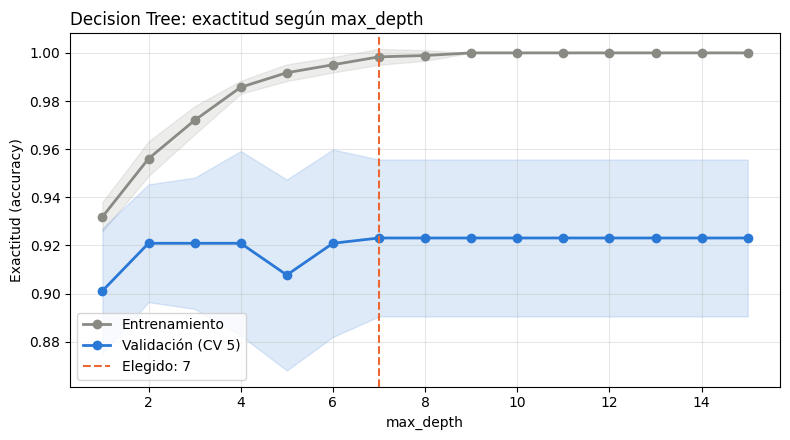

Mejor max_depth: 7  (validación = 0.9231 ± 0.0326)


,max_depth,acc_entrenamiento,acc_validacion,std_validacion
0,1,0.9319,0.9011,0.0260
1,2,0.9560,0.9209,0.0245
2,3,0.9720,0.9209,0.0273
3,4,0.9857,0.9209,0.0383
4,5,0.9918,0.9077,0.0397
5,6,0.9951,0.9209,0.0389
6,7,0.9984,0.9231,0.0326
7,8,0.9989,0.9231,0.0326
8,9,1.0000,0.9231,0.0326
9,10,1.0000,0.9231,0.0326


In [22]:
profundidades = list(range(1, 16))
mejor_depth, tabla_dt = curva_hiperparametro(
    DecisionTreeClassifier(random_state=SEMILLA), "max_depth", profundidades,
    "Decision Tree: exactitud según max_depth", "max_depth")
tabla_dt

Con poca profundidad el árbol subajusta. A medida que crece, la exactitud de entrenamiento llega a 1.0 (memoriza los datos) mientras que la de validación se estanca o baja: eso es sobreajuste. La profundidad elegida es el punto donde la validación es máxima.

### 3.2 Random Forest: curva de aprendizaje para `n_estimators`

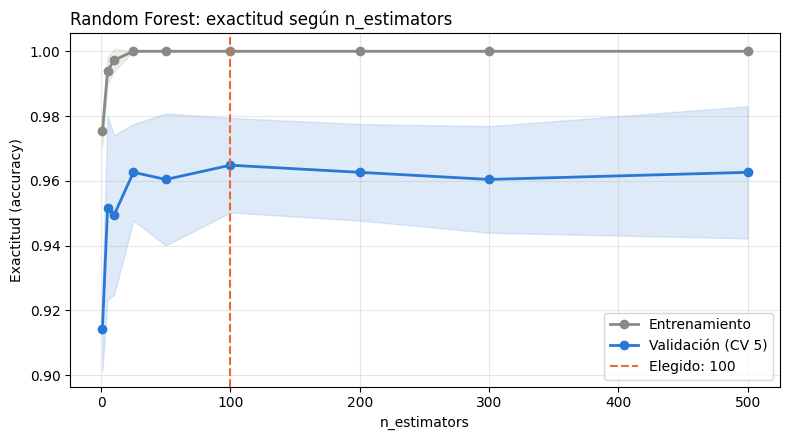

Mejor n_estimators: 100  (validación = 0.9648 ± 0.0146)


,n_estimators,acc_entrenamiento,acc_validacion,std_validacion
0,1,0.9753,0.9143,0.0128
1,5,0.9940,0.9516,0.0283
2,10,0.9973,0.9495,0.0247
3,25,1.0000,0.9626,0.0149
4,50,1.0000,0.9604,0.0204
5,100,1.0000,0.9648,0.0146
6,200,1.0000,0.9626,0.0149
7,300,1.0000,0.9604,0.0164
8,500,1.0000,0.9626,0.0204


In [23]:
n_arboles = [1, 5, 10, 25, 50, 100, 200, 300, 500]
mejor_n, tabla_rf = curva_hiperparametro(
    RandomForestClassifier(random_state=SEMILLA, n_jobs=-1), "n_estimators", n_arboles,
    "Random Forest: exactitud según n_estimators", "n_estimators")
tabla_rf

Con muy pocos árboles el bosque se comporta casi como un árbol individual. Al agregar árboles la validación mejora y luego se estabiliza: a partir de cierto punto más árboles solo aumentan el costo de cómputo sin mejorar la exactitud.

### 3.3 SVM: curva de aprendizaje para `kernel` (linear, poly, rbf)

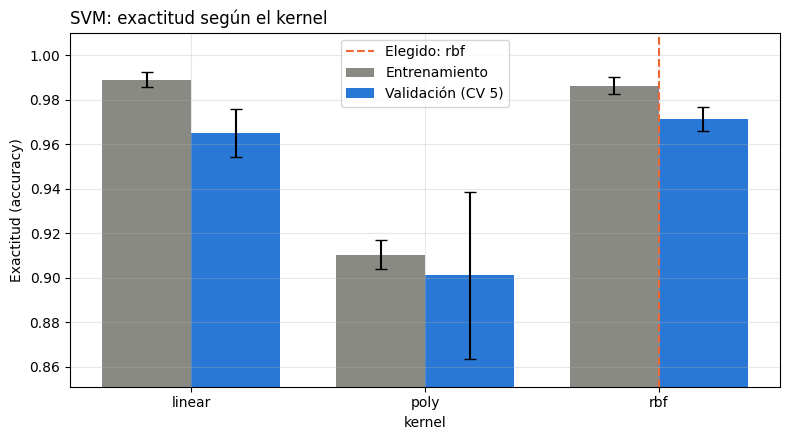

Mejor kernel: rbf  (validación = 0.9714 ± 0.0054)


,kernel,acc_entrenamiento,acc_validacion,std_validacion
0,linear,0.9890,0.9648,0.0108
1,poly,0.9104,0.9011,0.0374
2,rbf,0.9863,0.9714,0.0054


In [24]:
kernels = ["linear", "poly", "rbf"]
mejor_kernel, tabla_svm = curva_hiperparametro(
    make_pipeline(StandardScaler(), SVC(random_state=SEMILLA)), "svc__kernel", kernels,
    "SVM: exactitud según el kernel", "kernel", categorico=True)
tabla_svm

### 3.4 Modelos elegidos

Con los hiperparámetros seleccionados se definen los tres modelos finales. Como complemento se traza su curva de aprendizaje clásica (exactitud según la cantidad de datos de entrenamiento), que muestra si más datos ayudarían o si el modelo ya está sobreajustado.

Decision Tree -> max_depth = 7
Random Forest -> n_estimators = 100
SVM           -> kernel = 'rbf'


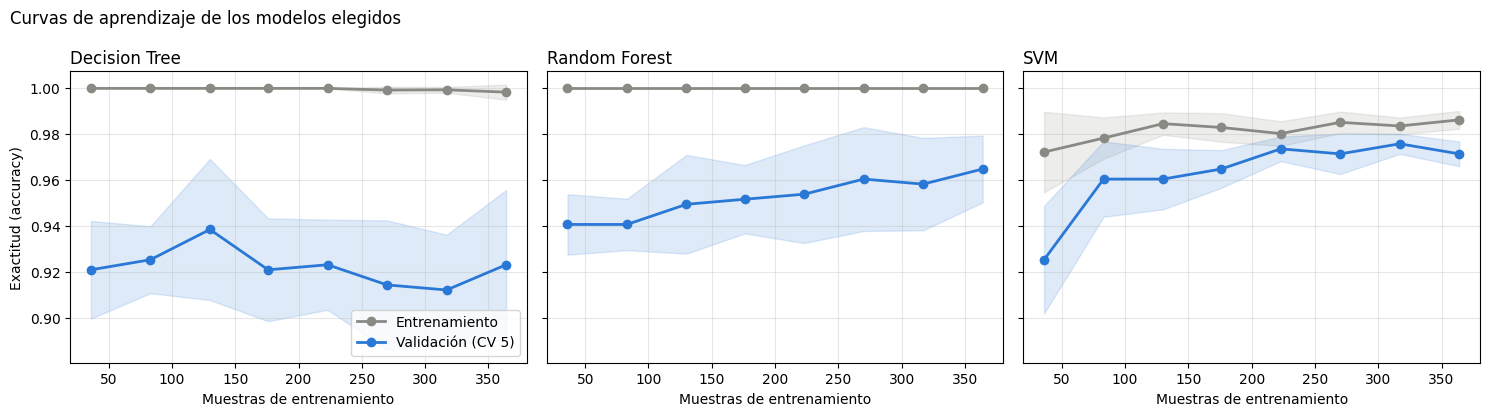

In [25]:
modelos = {
    "Decision Tree": DecisionTreeClassifier(max_depth=mejor_depth, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=mejor_n, random_state=SEMILLA, n_jobs=-1),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel=mejor_kernel, random_state=SEMILLA)),
}
print(f"Decision Tree -> max_depth = {mejor_depth}")
print(f"Random Forest -> n_estimators = {mejor_n}")
print(f"SVM           -> kernel = '{mejor_kernel}'")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    tam, tr, va = learning_curve(modelo, X_train, y_train, cv=CV5, scoring="accuracy",
                                 train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(tam, tr.mean(1), "o-", color=GRIS, lw=2, label="Entrenamiento")
    ax.fill_between(tam, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color=GRIS, alpha=0.15)
    ax.plot(tam, va.mean(1), "o-", color=AZUL, lw=2, label="Validación (CV 5)")
    ax.fill_between(tam, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=AZUL, alpha=0.15)
    ax.set_title(nombre, loc="left")
    ax.set_xlabel("Muestras de entrenamiento")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Exactitud (accuracy)")
axes[0].legend(loc="lower right")
fig.suptitle("Curvas de aprendizaje de los modelos elegidos", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 4. Validación cruzada: número de iteraciones

En validación cruzada *k-fold* el número de iteraciones es *k*: el entrenamiento se divide en *k* partes y el modelo se entrena *k* veces, validando cada vez en una parte distinta.

- Con *k* pequeño cada modelo se entrena con pocos datos y la estimación es pesimista.
- Con *k* grande cada fold de validación tiene muy pocas muestras (con *k* = 20 son ≈ 23), la desviación estándar crece y el costo se multiplica.

Se evalúan los tres modelos elegidos con *k* entre 2 y 20 y se calcula la exactitud media promedio de los tres modelos para cada *k*. Diferencias menores a 0.5 puntos porcentuales son más pequeñas que la variación entre folds (desviación de 2 a 5 puntos), así que no son una mejora real. Por eso se escoge el **menor *k* cuyo promedio queda a menos de 0.005 del mejor**: da la misma estimación con menos iteraciones y folds de validación más grandes.

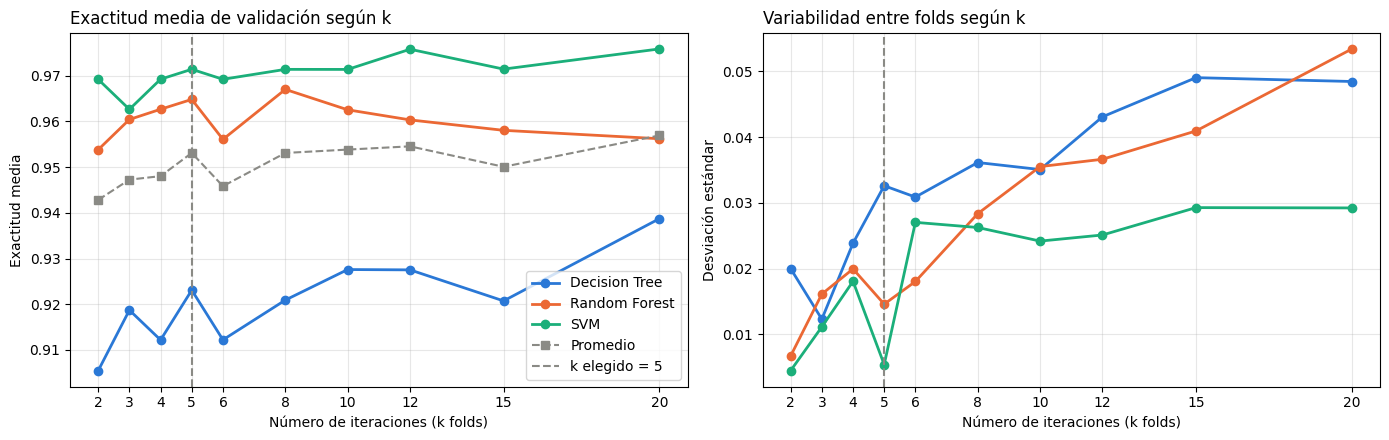

Mejor promedio: k = 20 (0.9569)
k elegido (menor k a menos de 0.005 del mejor): 5 (0.9531)



modelo,Decision Tree,Random Forest,SVM,Promedio
k,,,,
2,0.9055,0.9538,0.9692,0.9428
3,0.9187,0.9604,0.9627,0.9473
4,0.9122,0.9627,0.9693,0.9480
5,0.9231,0.9648,0.9714,0.9531
6,0.9122,0.9561,0.9692,0.9458
8,0.9209,0.9670,0.9714,0.9531
10,0.9276,0.9626,0.9714,0.9538
12,0.9275,0.9603,0.9758,0.9546
15,0.9207,0.9581,0.9715,0.9501


In [ ]:
valores_k = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
colores_modelo = {"Decision Tree": "#2a78d6", "Random Forest": "#eb6834",
                  "SVM": "#1baf7a", "Deep Learning (MLP)": "#eda100"}

filas = []
for k in valores_k:
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEMILLA)
    for nombre, modelo in modelos.items():
        s = cross_val_score(modelo, X_train, y_train, cv=cv_k, scoring="accuracy", n_jobs=-1)
        filas.append({"k": k, "modelo": nombre, "media": s.mean(), "std": s.std()})
res_cv = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, g in res_cv.groupby("modelo", sort=False):
    axes[0].plot(g["k"], g["media"], "o-", lw=2, color=colores_modelo[nombre], label=nombre)
    axes[1].plot(g["k"], g["std"], "o-", lw=2, color=colores_modelo[nombre], label=nombre)

promedio_k = res_cv.groupby("k")["media"].mean()
TOLERANCIA = 0.005
mejor_k = int(promedio_k[promedio_k >= promedio_k.max() - TOLERANCIA].index.min())
axes[0].plot(promedio_k.index, promedio_k.values, "s--", lw=1.5, color=GRIS, label="Promedio")
for ax in axes:
    ax.axvline(mejor_k, color=GRIS, ls="--", lw=1.5, label=f"k elegido = {mejor_k}")
    ax.set_xticks(valores_k)
    ax.set_xlabel("Número de iteraciones (k folds)")
    ax.grid(alpha=0.3)
axes[0].set_title("Exactitud media de validación según k", loc="left")
axes[0].set_ylabel("Exactitud media")
axes[1].set_title("Variabilidad entre folds según k", loc="left")
axes[1].set_ylabel("Desviación estándar")
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"Mejor promedio: k = {int(promedio_k.idxmax())} ({promedio_k.max():.4f})")
print(f"k elegido (menor k a menos de {TOLERANCIA} del mejor): {mejor_k} ({promedio_k[mejor_k]:.4f})\n")
tabla_cv = res_cv.pivot(index="k", columns="modelo", values="media").round(4)
tabla_cv["Promedio"] = promedio_k.round(4)
tabla_cv

In [ ]:
# Resultado de la validación cruzada con el k elegido
CVK = StratifiedKFold(n_splits=mejor_k, shuffle=True, random_state=SEMILLA)
resumen_cv = {}
for nombre, modelo in modelos.items():
    s = cross_val_score(modelo, X_train, y_train, cv=CVK, scoring="accuracy", n_jobs=-1)
    resumen_cv[nombre] = s
    print(f"{nombre:14s} accuracy CV({mejor_k}) = {s.mean():.4f} ± {s.std():.4f}")

Decision Tree  accuracy CV(5) = 0.9231 ± 0.0326
Random Forest  accuracy CV(5) = 0.9648 ± 0.0146
SVM            accuracy CV(5) = 0.9714 ± 0.0054


## 5. Deep learning: perceptrón multicapa (MLP)

Se construyen tres redes densas con la misma entrada (30 variables) y la misma salida (1 neurona sigmoide que da la probabilidad de maligno). Solo cambia la profundidad:

| Red | Capas ocultas | Neuronas |
|---|---|---|
| MLP-3 | 3 | 64, 128, 128 |
| MLP-6 | 6 | 64, 64, 128, 128, 256, 256 |
| MLP-10 | 10 | 128 en cada capa |

Todas usan ReLU en las capas ocultas, optimizador Adam y pérdida `binary_crossentropy`.

Para elegir arquitectura y epochs sin tocar el conjunto de prueba, el 80 % de entrenamiento se divide otra vez en **entrenamiento de la red (80 %)** y **validación (20 %)**. El `StandardScaler` se ajusta solo con los datos de entrenamiento de la red.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ARQUITECTURAS = {
    "MLP-3":  [64, 128, 128],
    "MLP-6":  [64, 64, 128, 128, 256, 256],
    "MLP-10": [128] * 10,
}
colores_arq = {"MLP-3": "#2a78d6", "MLP-6": "#eb6834", "MLP-10": "#1baf7a"}

def construir_mlp(capas_ocultas, n_entradas):
    modelo = keras.Sequential([keras.Input(shape=(n_entradas,))])
    for n in capas_ocultas:
        modelo.add(layers.Dense(n, activation="relu"))
    modelo.add(layers.Dense(1, activation="sigmoid"))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

# Sub-partición del 80 % de entrenamiento: entrenamiento de la red / validación
X_tr_dl, X_val_dl, y_tr_dl, y_val_dl = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEMILLA)
escalador_dl = StandardScaler().fit(X_tr_dl)
X_tr_dl_s = escalador_dl.transform(X_tr_dl)
X_val_dl_s = escalador_dl.transform(X_val_dl)
y_tr_dl, y_val_dl = y_tr_dl.to_numpy(), y_val_dl.to_numpy()
print(f"Entrenamiento red: {X_tr_dl_s.shape}   Validación: {X_val_dl_s.shape}")

for nombre, capas in ARQUITECTURAS.items():
    print(f"{nombre}: {len(capas)} capas ocultas, "
          f"{construir_mlp(capas, X.shape[1]).count_params():,} parámetros")

Entrenamiento red: (364, 30)   Validación: (91, 30)
MLP-3: 3 capas ocultas, 26,945 parámetros
MLP-6: 6 capas ocultas, 130,049 parámetros
MLP-10: 10 capas ocultas, 152,705 parámetros


### 5.1 Entrenamiento de las tres arquitecturas

Cada red se entrena 100 epochs y se registra la pérdida y la exactitud en entrenamiento y validación después de cada epoch.

MLP-3: acc validación final = 0.9670   pérdida validación mínima = 0.0763 (epoch 6)
MLP-6: acc validación final = 0.9560   pérdida validación mínima = 0.0833 (epoch 6)
MLP-10: acc validación final = 0.9670   pérdida validación mínima = 0.0637 (epoch 11)


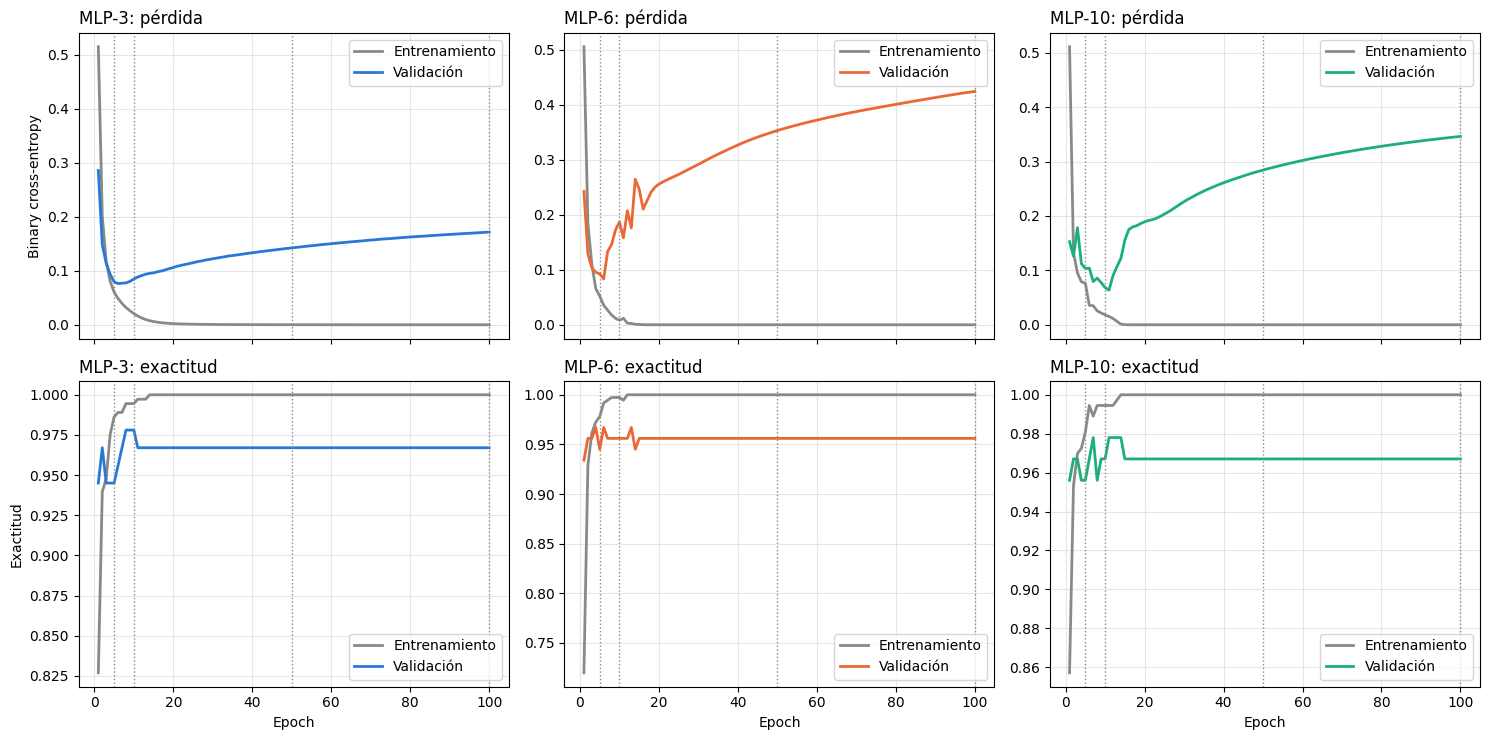

In [ ]:
historiales = {}
for nombre, capas in ARQUITECTURAS.items():
    keras.utils.set_random_seed(SEMILLA)
    red = construir_mlp(capas, X.shape[1])
    h = red.fit(X_tr_dl_s, y_tr_dl, validation_data=(X_val_dl_s, y_val_dl),
                epochs=100, batch_size=32, verbose=0)
    historiales[nombre] = h.history
    print(f"{nombre}: acc validación final = {h.history['val_accuracy'][-1]:.4f}   "
          f"pérdida validación mínima = {min(h.history['val_loss']):.4f} "
          f"(epoch {int(np.argmin(h.history['val_loss'])) + 1})")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for j, (nombre, hist) in enumerate(historiales.items()):
    ep = np.arange(1, len(hist["loss"]) + 1)
    axes[0, j].plot(ep, hist["loss"], color=GRIS, lw=2, label="Entrenamiento")
    axes[0, j].plot(ep, hist["val_loss"], color=colores_arq[nombre], lw=2, label="Validación")
    axes[0, j].set_title(f"{nombre}: pérdida", loc="left")
    axes[1, j].plot(ep, hist["accuracy"], color=GRIS, lw=2, label="Entrenamiento")
    axes[1, j].plot(ep, hist["val_accuracy"], color=colores_arq[nombre], lw=2, label="Validación")
    axes[1, j].set_title(f"{nombre}: exactitud", loc="left")
    axes[1, j].set_xlabel("Epoch")
    for ax in axes[:, j]:
        for e in [5, 10, 50, 100]:
            ax.axvline(e, color=GRIS, ls=":", lw=1)
        ax.grid(alpha=0.3)
        ax.legend()
axes[0, 0].set_ylabel("Binary cross-entropy")
axes[1, 0].set_ylabel("Exactitud")
plt.tight_layout()
plt.show()

Las líneas punteadas marcan 5, 10, 50 y 100 epochs. Cuando la pérdida de validación deja de bajar y empieza a subir mientras la de entrenamiento sigue cayendo, la red está memorizando el conjunto de entrenamiento (sobreajuste). Las redes más profundas tienen muchos más parámetros para solo ~364 muestras, así que tienden a sobreajustar antes.

## 6. Epochs: experimento con 5, 10, 50 y 100

Para demostrar cuál número de epochs conviene, se hace un experimento por cada valor: para cada combinación de arquitectura y epochs se entrena una red **nueva desde cero** y se mide en el conjunto de validación. Cada combinación se repite con 3 semillas distintas y se promedia, porque con solo 91 muestras de validación una sola corrida puede variar por azar.

Criterio de elección: mayor exactitud media de validación; en empate, menor pérdida de validación (probabilidades mejor calibradas) y luego menos epochs.

Experimento con 5 epochs terminado
Experimento con 10 epochs terminado
Experimento con 50 epochs terminado
Experimento con 100 epochs terminado


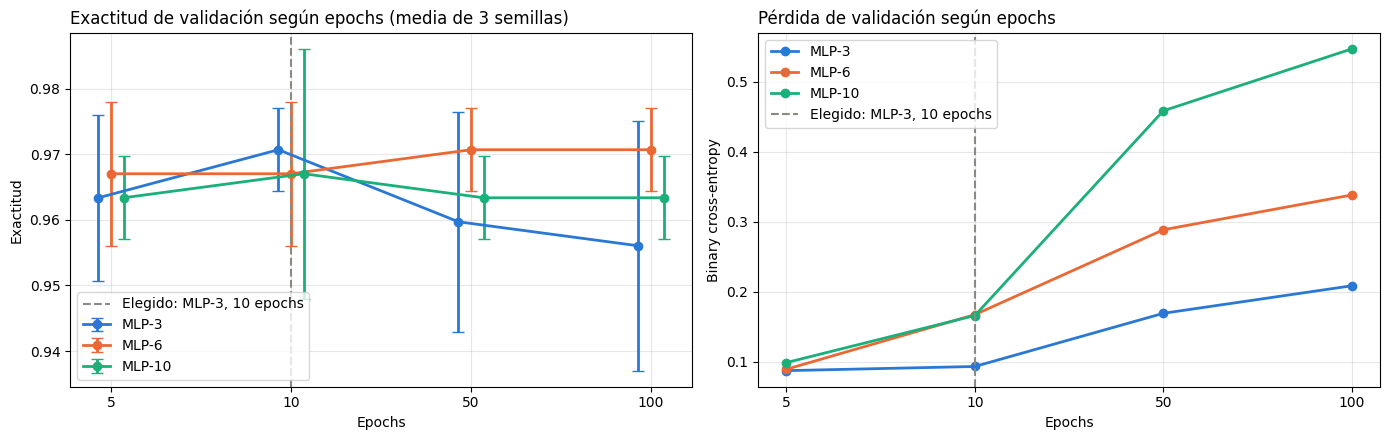

Configuración elegida: MLP-3 con 10 epochs (acc validación = 0.9707 ± 0.0063)



arquitectura,MLP-10,MLP-3,MLP-6
epochs,,,
5,0.9634,0.9634,0.9670
10,0.9670,0.9707,0.9670
50,0.9634,0.9597,0.9707
100,0.9634,0.9560,0.9707


In [ ]:
EPOCHS = [5, 10, 50, 100]
SEMILLAS_DL = [0, 1, 2]

filas = []
for n_epochs in EPOCHS:
    for nombre, capas in ARQUITECTURAS.items():
        for s in SEMILLAS_DL:
            keras.utils.set_random_seed(s)
            red = construir_mlp(capas, X.shape[1])
            red.fit(X_tr_dl_s, y_tr_dl, epochs=n_epochs, batch_size=32, verbose=0)
            perdida, acc = red.evaluate(X_val_dl_s, y_val_dl, verbose=0)
            filas.append({"epochs": n_epochs, "arquitectura": nombre, "semilla": s,
                          "acc_validacion": acc, "perdida_validacion": perdida})
    print(f"Experimento con {n_epochs} epochs terminado")

res_epochs = (pd.DataFrame(filas)
              .groupby(["arquitectura", "epochs"], sort=False)
              .agg(acc_media=("acc_validacion", "mean"), acc_std=("acc_validacion", "std"),
                   perdida_media=("perdida_validacion", "mean"))
              .reset_index())

mejor = res_epochs.sort_values(["acc_media", "perdida_media", "epochs"],
                               ascending=[False, True, True]).iloc[0]
mejor_arq, mejor_epochs = mejor["arquitectura"], int(mejor["epochs"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pos = np.arange(len(EPOCHS))
for j, (nombre, g) in enumerate(res_epochs.groupby("arquitectura", sort=False)):
    axes[0].errorbar(pos + (j - 1) * 0.07, g["acc_media"], yerr=g["acc_std"], fmt="o-", lw=2, capsize=4,
                     color=colores_arq[nombre], label=nombre)
    axes[1].plot(pos, g["perdida_media"], "o-", lw=2, color=colores_arq[nombre], label=nombre)
for ax in axes:
    ax.set_xticks(pos, EPOCHS)
    ax.set_xlabel("Epochs")
    ax.axvline(EPOCHS.index(mejor_epochs), color=GRIS, ls="--", lw=1.5,
               label=f"Elegido: {mejor_arq}, {mejor_epochs} epochs")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title("Exactitud de validación según epochs (media de 3 semillas)", loc="left")
axes[0].set_ylabel("Exactitud")
axes[1].set_title("Pérdida de validación según epochs", loc="left")
axes[1].set_ylabel("Binary cross-entropy")
plt.tight_layout()
plt.show()

print(f"Configuración elegida: {mejor_arq} con {mejor_epochs} epochs "
      f"(acc validación = {mejor['acc_media']:.4f} ± {mejor['acc_std']:.4f})\n")
res_epochs.pivot(index="epochs", columns="arquitectura", values="acc_media").round(4)

Con 5 o 10 epochs la red todavía no termina de aprender (subajuste, sobre todo en las redes profundas). Con demasiados epochs la exactitud se mantiene pero la pérdida de validación sube, señal de sobreajuste. El número elegido es el que da el mejor equilibrio en validación.

### 6.1 Red final

La arquitectura y los epochs elegidos se reentrenan con todo el 80 % de entrenamiento (escalador ajustado de nuevo sobre ese 80 %) para evaluarlos en el conjunto de prueba, igual que los demás modelos.

In [ ]:
escalador_final = StandardScaler().fit(X_train)
X_train_s = escalador_final.transform(X_train)
X_test_s = escalador_final.transform(X_test)

keras.utils.set_random_seed(SEMILLA)
red_final = construir_mlp(ARQUITECTURAS[mejor_arq], X.shape[1])
red_final.fit(X_train_s, y_train.to_numpy(), epochs=mejor_epochs, batch_size=32, verbose=0)
red_final.summary()

Model: "sequential_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_308 (Dense)               │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_309 (Dense)               │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_310 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_311 (Dense)               │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,837 (315.77 KB)

 Trainable params: 26,945 (105.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 53,892 (210.52 KB)

## Desempeño final: DT, RF, SVM y DL

Los cuatro modelos se entrenan con el 80 % de entrenamiento y se evalúan **una sola vez** en el 20 % de prueba, que no se usó en ninguna decisión anterior.

Además de la exactitud se reportan precisión, recall y F1 de la clase maligna, y el AUC-ROC. En este problema el **recall de M** es la métrica más importante: un falso negativo es un tumor maligno clasificado como benigno.

In [ ]:
def metricas(y_real, y_pred, y_puntaje):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precisión (M)": precision_score(y_real, y_pred),
            "Recall (M)": recall_score(y_real, y_pred),
            "F1 (M)": f1_score(y_real, y_pred),
            "AUC-ROC": roc_auc_score(y_real, y_puntaje)}

resultados, predicciones = {}, {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    puntaje = (modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba")
               else modelo.decision_function(X_test))
    resultados[nombre] = metricas(y_test, pred, puntaje)
    predicciones[nombre] = pred

prob_dl = red_final.predict(X_test_s, verbose=0).ravel()
pred_dl = (prob_dl >= 0.5).astype(int)
nombre_dl = "Deep Learning (MLP)"
resultados[nombre_dl] = metricas(y_test, pred_dl, prob_dl)
predicciones[nombre_dl] = pred_dl

tabla_final = pd.DataFrame(resultados).T
tabla_final.round(4)

,Accuracy,Precisión (M),Recall (M),F1 (M),AUC-ROC
Decision Tree,0.9386,0.9487,0.8810,0.9136,0.9225
Random Forest,0.9737,1.0000,0.9286,0.9630,0.9929
SVM,0.9737,1.0000,0.9286,0.9630,0.9947
Deep Learning (MLP),0.9737,1.0000,0.9286,0.9630,0.9904


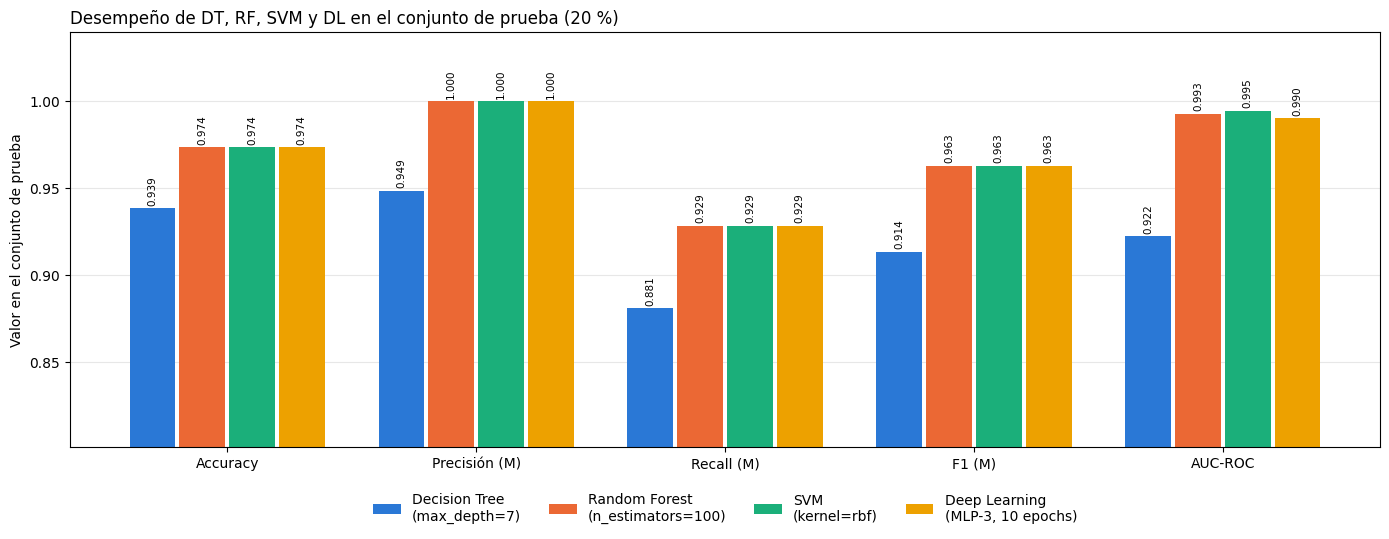

Mejor modelo por métrica:
  Accuracy       -> Random Forest (0.9737)
  Precisión (M)  -> Random Forest (1.0000)
  Recall (M)     -> Random Forest (0.9286)
  F1 (M)         -> Random Forest (0.9630)
  AUC-ROC        -> SVM (0.9947)


In [ ]:
nombres = list(resultados.keys())
etiquetas_modelo = {
    "Decision Tree": f"Decision Tree\n(max_depth={mejor_depth})",
    "Random Forest": f"Random Forest\n(n_estimators={mejor_n})",
    "SVM": f"SVM\n(kernel={mejor_kernel})",
    nombre_dl: f"Deep Learning\n({mejor_arq}, {mejor_epochs} epochs)",
}
metricas_cols = list(tabla_final.columns)
x = np.arange(len(metricas_cols))
ancho = 0.2

fig, ax = plt.subplots(figsize=(14, 5.5))
for i, nombre in enumerate(nombres):
    valores = tabla_final.loc[nombre].values
    barras = ax.bar(x + (i - 1.5) * ancho, valores, ancho * 0.92,
                    color=colores_modelo[nombre], label=etiquetas_modelo[nombre])
    ax.bar_label(barras, fmt="%.3f", fontsize=7.5, padding=2, rotation=90)
ax.set_xticks(x, metricas_cols)
ax.set_ylim(max(0, tabla_final.values.min() - 0.08), 1.04)
ax.set_ylabel("Valor en el conjunto de prueba")
ax.set_title("Desempeño de DT, RF, SVM y DL en el conjunto de prueba (20 %)", loc="left")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

print("Mejor modelo por métrica:")
for m in metricas_cols:
    print(f"  {m:14s} -> {tabla_final[m].idxmax()} ({tabla_final[m].max():.4f})")

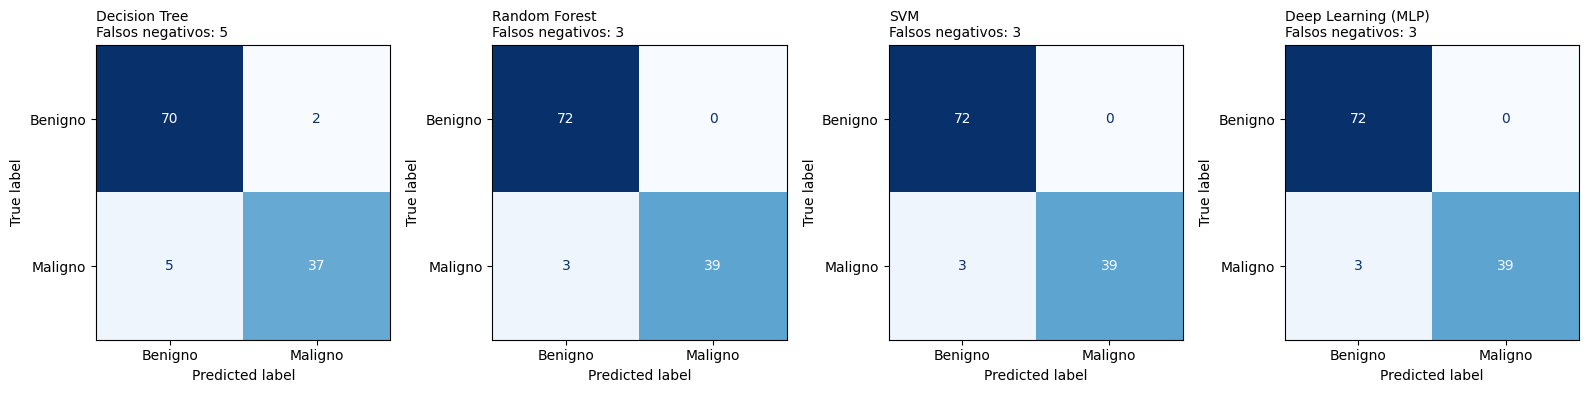

In [ ]:
# Matrices de confusión: dónde se equivoca cada modelo
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, nombre in zip(axes, nombres):
    cm = confusion_matrix(y_test, predicciones[nombre])
    ConfusionMatrixDisplay(cm, display_labels=["Benigno", "Maligno"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nombre}\nFalsos negativos: {cm[1, 0]}", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### Conclusiones

- Las curvas de aprendizaje permitieron elegir `max_depth` del árbol, `n_estimators` del bosque y el `kernel` de la SVM usando solo los datos de entrenamiento.
- La curva de validación cruzada muestra que la exactitud media cambia poco con *k*, pero la variabilidad aumenta con *k* grande; el *k* elegido equilibra estimación y estabilidad.
- En el MLP, más capas no significa mejor desempeño: con 455 muestras las redes profundas tienen cientos de miles de parámetros y sobreajustan con facilidad. El experimento de epochs demuestra el punto entre subajuste y sobreajuste.
- La comparación final en el conjunto de prueba (barplot) muestra qué modelo generaliza mejor. Para un uso clínico conviene priorizar el modelo con mayor **recall de la clase maligna** (menos falsos negativos), revisando la matriz de confusión.

# TERCERA ETAPA: APRENDIZAJE NO SUPERVISADO

En las etapas anteriores se usó el diagnóstico como etiqueta para entrenar clasificadores (aprendizaje **supervisado**). En esta etapa se hace lo contrario: se agrupan los tumores **sin mirar el diagnóstico**, para ver si la estructura de los datos por sí sola separa los casos benignos de los malignos.

1. Escalado de los datos con `StandardScaler`
2. Reducción de dimensionalidad con PCA: 30 variables → 2 componentes
3. K-Means sobre las 2 componentes, con `n_clusters` = número de clases del dataset (2)
4. DBSCAN sobre las 2 componentes, buscando y justificando `eps` y `min_samples`
5. Gráficos comparativos: datos originales, K-Means y DBSCAN

El diagnóstico real solo se usa **al final**, como referencia para medir qué tan bien coinciden los grupos encontrados con las clases verdaderas.

## 1. Escalado de los datos

Las 30 variables están en escalas muy distintas: `area_mean` llega a 2500 mientras que `smoothness_mean` no pasa de 0.16. Tanto PCA como K-Means y DBSCAN se basan en **distancias**, así que sin escalar las variables de valores grandes dominarían por completo el resultado.

Se usa `StandardScaler`, que transforma cada columna a media 0 y desviación estándar 1:

$$z = \frac{x - \mu}{\sigma}$$

Es el escalador habitual antes de PCA, porque PCA busca las direcciones de máxima **varianza** y necesita que todas las variables aporten en igualdad de condiciones.

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

AZUL, NARANJA, VERDE, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"

# Predictoras y diagnóstico real (solo se usa para evaluar, NO para agrupar)
X = df.drop(columns="diagnosis")
y = df["diagnosis"]
y_num = y.map({"M": 1, "B": 0})

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)

print(f"X escalada: {X_esc.shape}")
print(f"Media de cada columna  -> mín {X_esc.mean(axis=0).min():+.1e}  máx {X_esc.mean(axis=0).max():+.1e}")
print(f"Desv. estándar         -> mín {X_esc.std(axis=0).min():.4f}   máx {X_esc.std(axis=0).max():.4f}")

pd.DataFrame({
    "antes (media)": X.mean(), "antes (desv)": X.std(),
    "después (media)": X_esc.mean(axis=0), "después (desv)": X_esc.std(axis=0),
}).head(8).round(4)

X escalada: (569, 30)
Media de cada columna  -> mín -8.4e-16  máx +4.7e-16
Desv. estándar         -> mín 1.0000   máx 1.0000


,antes (media),antes (desv),después (media),después (desv)
radius_mean,14.1273,3.5240,-0.0,1.0
texture_mean,19.2896,4.3010,0.0,1.0
perimeter_mean,91.9690,24.2990,-0.0,1.0
area_mean,654.8891,351.9141,-0.0,1.0
smoothness_mean,0.0964,0.0141,-0.0,1.0
compactness_mean,0.1043,0.0528,0.0,1.0
concavity_mean,0.0888,0.0797,0.0,1.0
concave points_mean,0.0489,0.0388,-0.0,1.0


## 2. Reducción de dimensionalidad con PCA (2 componentes)

PCA construye nuevas variables (componentes principales) que son combinaciones lineales de las 30 originales, ordenadas de mayor a menor varianza explicada. Reducir a 2 componentes permite **graficar los datos en un plano** y le quita a los algoritmos de agrupamiento la redundancia que se detectó en la etapa 1 (`radius`, `perimeter` y `area` miden prácticamente lo mismo).

Dimensiones: 30 variables -> 2 componentes
PC1 explica 44.27% de la varianza
PC2 explica 18.97%
Las 2 componentes conservan el 63.24% de la varianza original


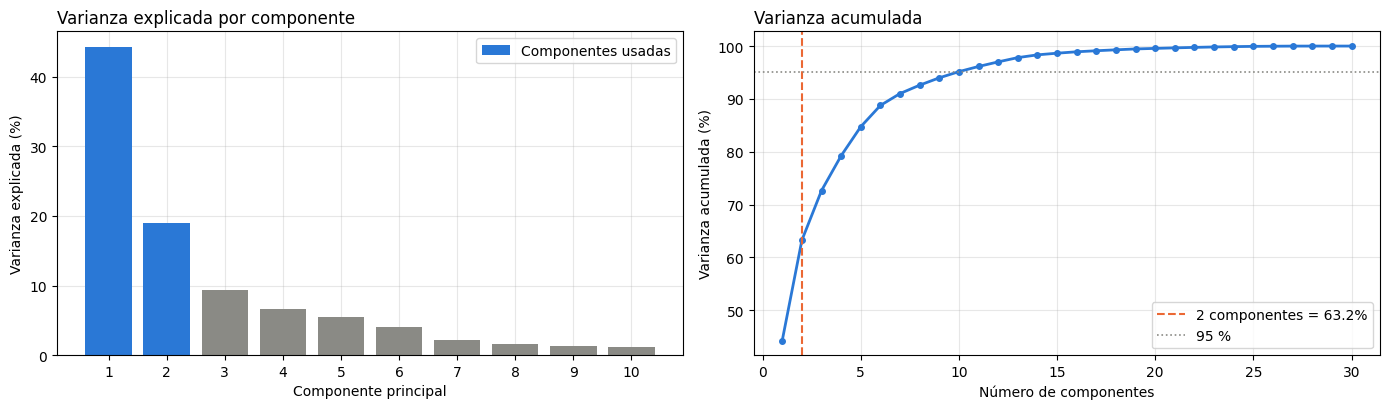


Variables con mayor peso en PC1:
concave points_mean     0.261
concavity_mean          0.258
concave points_worst    0.251
compactness_mean        0.239
perimeter_worst         0.237

Variables con mayor peso en PC2:
fractal_dimension_mean     0.367
fractal_dimension_se       0.280
fractal_dimension_worst    0.275
radius_mean                0.234
compactness_se             0.233


In [27]:
SEMILLA = 42
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_esc)
var = pca.explained_variance_ratio_

print(f"Dimensiones: {X_esc.shape[1]} variables -> {X_pca.shape[1]} componentes")
print(f"PC1 explica {var[0]:.2%} de la varianza")
print(f"PC2 explica {var[1]:.2%}")
print(f"Las 2 componentes conservan el {var.sum():.2%} de la varianza original")

# Varianza explicada de todas las componentes posibles, para ver qué se pierde
pca_todas = PCA().fit(X_esc)
acum = np.cumsum(pca_todas.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(range(1, 11), pca_todas.explained_variance_ratio_[:10] * 100, color=GRIS)
axes[0].bar([1, 2], var * 100, color=AZUL, label="Componentes usadas")
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel("Componente principal"); axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_title("Varianza explicada por componente", loc="left"); axes[0].legend()

axes[1].plot(range(1, len(acum) + 1), acum * 100, "o-", color=AZUL, lw=2, ms=4)
axes[1].axvline(2, color=NARANJA, ls="--", lw=1.5, label=f"2 componentes = {var.sum():.1%}")
axes[1].axhline(95, color=GRIS, ls=":", lw=1.2, label="95 %")
axes[1].set_xlabel("Número de componentes"); axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title("Varianza acumulada", loc="left"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# Variables que más pesan en cada componente
cargas = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print("\nVariables con mayor peso en PC1:")
print(cargas["PC1"].abs().sort_values(ascending=False).head(5).round(3).to_string())
print("\nVariables con mayor peso en PC2:")
print(cargas["PC2"].abs().sort_values(ascending=False).head(5).round(3).to_string())

Las dos primeras componentes conservan cerca del **63 %** de la varianza original. Se pierde información (harían falta unas 10 componentes para llegar al 95 %), pero a cambio se obtiene una representación en dos dimensiones que se puede visualizar y en la que los algoritmos de agrupamiento trabajan sin la redundancia entre variables.

- **PC1** está dominada por las variables de tamaño e irregularidad del contorno (`concave points`, `concavity`, `perimeter`): es, en la práctica, un eje de "qué tan grande e irregular es el tumor".
- **PC2** está dominada por la dimensión fractal y la compacidad, que describen la textura del borde.

## 3. K-Means con `n_clusters` = 2

El dataset tiene **2 clases** (maligno y benigno), así que se usa `n_clusters = 2`. K-Means ubica 2 centroides y asigna cada punto al más cercano, minimizando la distancia dentro de cada grupo.

Para evaluar el resultado se usan tres medidas:

- **Coeficiente de silueta:** qué tan compactos y separados quedan los grupos. Va de −1 a 1 y **no usa el diagnóstico**.
- **ARI (Adjusted Rand Index):** cuánto coinciden los grupos con el diagnóstico real. 1 es coincidencia perfecta y 0 es lo que daría el azar.
- **NMI (Normalized Mutual Information):** cuánta información comparten los grupos y el diagnóstico.

In [28]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA)
etq_km = kmeans.fit_predict(X_pca)

# Las etiquetas de cluster (0/1) son arbitrarias: se renombran según la clase
# mayoritaria de cada grupo, solo para poder comparar los colores con el diagnóstico real.
tabla = pd.crosstab(y, etq_km)
mapa_km = {c: ("M" if tabla.loc["M", c] > tabla.loc["B", c] else "B") for c in tabla.columns}
if mapa_km[0] == "M":                      # cluster 0 debe quedar asociado a B
    etq_km = 1 - etq_km
    kmeans.cluster_centers_ = kmeans.cluster_centers_[::-1]

sil_km = silhouette_score(X_pca, etq_km)
ari_km = adjusted_rand_score(y_num, etq_km)
nmi_km = normalized_mutual_info_score(y_num, etq_km)
tabla_km = pd.crosstab(y, etq_km).rename(columns={0: "Cluster 0", 1: "Cluster 1"})
concordancia = (tabla_km.values[0, 0] + tabla_km.values[1, 1]) / len(y)

print(f"Coeficiente de silueta : {sil_km:.4f}   (qué tan compactos y separados son los grupos)")
print(f"ARI vs diagnóstico     : {ari_km:.4f}   (1 = coincidencia perfecta, 0 = azar)")
print(f"NMI vs diagnóstico     : {nmi_km:.4f}")
print(f"Concordancia           : {concordancia:.2%} de los tumores caen en el cluster de su propia clase\n")
tabla_km

Coeficiente de silueta : 0.5085   (qué tan compactos y separados son los grupos)
ARI vs diagnóstico     : 0.6592   (1 = coincidencia perfecta, 0 = azar)
NMI vs diagnóstico     : 0.5404
Concordancia           : 90.69% de los tumores caen en el cluster de su propia clase



col_0,Cluster 0,Cluster 1
diagnosis,,
B,341,16
M,37,175


**Resultado:** K-Means recupera bastante bien la estructura de las clases. La concordancia con el diagnóstico real es del **90.7 %** y el ARI de **0.659**, que es alto considerando que el algoritmo nunca vio las etiquetas.

Los errores se concentran en la zona donde ambas clases se tocan, visible en los gráficos del punto 5: los tumores malignos pequeños y regulares caen dentro del grupo de los benignos. Es la misma frontera difusa que se veía en los boxplots de la etapa 1.

Conviene notar que un clasificador supervisado llegó al 97.4 % en la etapa 2. La diferencia es esperable: el clasificador aprende de las etiquetas, mientras que K-Means solo encuentra los dos grupos más compactos que existen en los datos.

## 4. DBSCAN: búsqueda de `eps` y `min_samples`

DBSCAN agrupa por **densidad**: un punto es "núcleo" si tiene al menos `min_samples` vecinos dentro de un radio `eps`; los puntos que no alcanzan ninguna zona densa quedan marcados como **ruido** (etiqueta −1). A diferencia de K-Means, no hay que decirle cuántos grupos buscar, pero sí hay que elegir bien esos dos parámetros.

### 4.1 Elección de `min_samples`

La regla práctica más usada es `min_samples ≥ 2 × número de dimensiones`. Como se trabaja sobre las 2 componentes de PCA, el mínimo sería 4. Se usa **5** (el valor por defecto de scikit-learn), un poco más exigente, para que un punto aislado no forme grupo por su cuenta.

### 4.2 Elección de `eps` con la curva de k-distancias

El método estándar es la **curva de k-distancias**: para cada punto se calcula la distancia a su k-ésimo vecino más cercano (con k = `min_samples`), se ordenan esas distancias de menor a mayor y se grafican. La curva crece despacio mientras recorre los puntos que están en zonas densas y se dispara cuando llega a los puntos aislados. **El codo de esa curva es el valor de `eps`**: por debajo quedan las distancias "normales" dentro de un grupo y por encima las distancias de los puntos que deben considerarse ruido.

El codo se ubica de forma automática como el punto más alejado de la recta que une los dos extremos de la curva, para no depender de la apreciación visual.

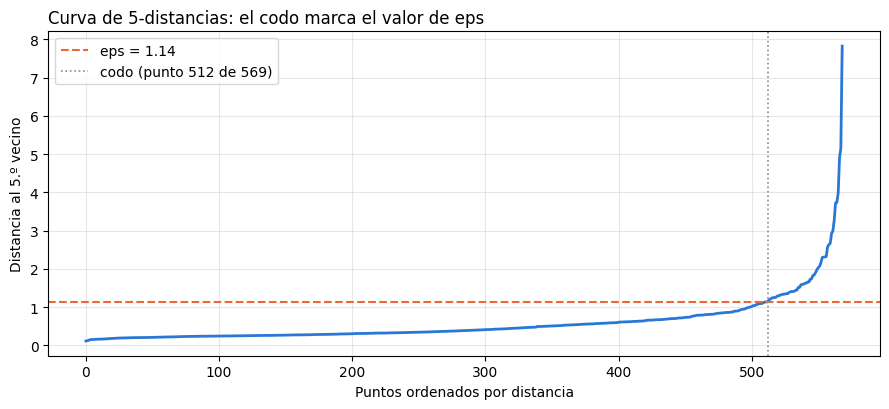

min_samples = 5
eps = 1.14  (distancia al 5.º vecino en el codo de la curva)


In [29]:
# min_samples: regla práctica min_samples >= 2 x nº de dimensiones.
# Con 2 componentes el mínimo sería 4; se usa 5 (valor por defecto de scikit-learn)
# para que un punto necesite algo más de evidencia antes de ser considerado núcleo.
MIN_SAMPLES = 5

vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_pca)
distancias, _ = vecinos.kneighbors(X_pca)
k_dist = np.sort(distancias[:, -1])          # distancia al 5.º vecino, ordenada

# Codo: punto más alejado de la recta que une los dos extremos de la curva
n = len(k_dist); idx = np.arange(n)
x1, yy1, x2, yy2 = 0, k_dist[0], n - 1, k_dist[-1]
dist_recta = np.abs((yy2 - yy1) * idx - (x2 - x1) * k_dist + x2 * yy1 - yy2 * x1) / np.hypot(yy2 - yy1, x2 - x1)
i_codo = int(np.argmax(dist_recta))
EPS = float(round(k_dist[i_codo], 2))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(idx, k_dist, color=AZUL, lw=2)
ax.axhline(EPS, color=NARANJA, ls="--", lw=1.5, label=f"eps = {EPS}")
ax.axvline(i_codo, color=GRIS, ls=":", lw=1.2, label=f"codo (punto {i_codo} de {n})")
ax.set_xlabel("Puntos ordenados por distancia")
ax.set_ylabel(f"Distancia al {MIN_SAMPLES}.º vecino")
ax.set_title(f"Curva de {MIN_SAMPLES}-distancias: el codo marca el valor de eps", loc="left")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

print(f"min_samples = {MIN_SAMPLES}")
print(f"eps = {EPS}  (distancia al {MIN_SAMPLES}.º vecino en el codo de la curva)")

### 4.3 Análisis de sensibilidad

Antes de fijar los parámetros, se revisa cómo cambian los resultados al variar `eps` y `min_samples`. Esto respalda la elección y muestra que no es arbitraria: con `eps` pequeño casi todo es ruido y aparecen muchos grupos diminutos; con `eps` grande todo colapsa en un solo grupo. El valor del codo cae justo en la zona estable, donde el porcentaje de ruido ya se aplanó.

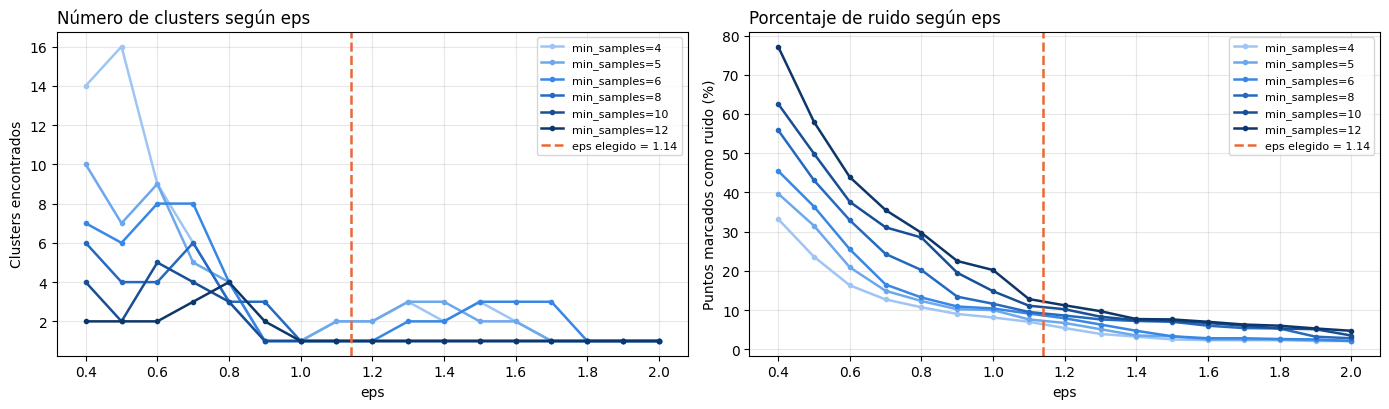

Comportamiento alrededor de la configuración elegida (min_samples = 5):


,min_samples,eps,clusters,ruido_%,silueta,ARI
22,5,0.9,1,10.2,NaN,0.087
23,5,1.0,1,10.0,NaN,0.084
24,5,1.1,2,7.6,0.433,0.070
25,5,1.2,2,6.7,0.425,0.056
26,5,1.3,3,5.1,0.368,0.052
27,5,1.4,3,3.5,0.359,0.042


In [30]:
# Sensibilidad: cómo cambian los resultados alrededor de los valores elegidos
filas = []
for ms in [4, 5, 6, 8, 10, 12]:
    for eps in np.arange(0.4, 2.01, 0.1):
        etq = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
        n_cl = len(set(etq)) - (1 if -1 in etq else 0)
        es_ruido = etq == -1
        sil = (silhouette_score(X_pca[~es_ruido], etq[~es_ruido])
               if n_cl >= 2 and (~es_ruido).sum() > n_cl else np.nan)
        filas.append({"min_samples": ms, "eps": round(eps, 2), "clusters": n_cl,
                      "ruido_%": round(es_ruido.mean() * 100, 1),
                      "silueta": round(sil, 3) if sil == sil else None,
                      "ARI": round(adjusted_rand_score(y_num, etq), 3)})
rejilla = pd.DataFrame(filas)

# min_samples es una variable ordenada: se usa una rampa de un solo color (claro -> oscuro)
RAMPA = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for color, (ms, g) in zip(RAMPA, rejilla.groupby("min_samples")):
    axes[0].plot(g["eps"], g["clusters"], "o-", ms=3, lw=1.8, color=color, label=f"min_samples={ms}")
    axes[1].plot(g["eps"], g["ruido_%"], "o-", ms=3, lw=1.8, color=color, label=f"min_samples={ms}")
for ax, t, yl in zip(axes, ["Número de clusters según eps", "Porcentaje de ruido según eps"],
                     ["Clusters encontrados", "Puntos marcados como ruido (%)"]):
    ax.axvline(EPS, color=NARANJA, ls="--", lw=1.8, label=f"eps elegido = {EPS}")
    ax.set_xlabel("eps"); ax.set_ylabel(yl); ax.set_title(t, loc="left")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Comportamiento alrededor de la configuración elegida (min_samples = {MIN_SAMPLES}):")
rejilla[(rejilla.min_samples == MIN_SAMPLES) & rejilla.eps.between(EPS - 0.3, EPS + 0.3)]

In [31]:
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
etq_db = dbscan.fit_predict(X_pca)

es_ruido = etq_db == -1
n_clusters_db = len(set(etq_db)) - (1 if -1 in etq_db else 0)
sil_db = (silhouette_score(X_pca[~es_ruido], etq_db[~es_ruido])
          if n_clusters_db >= 2 else np.nan)
ari_db = adjusted_rand_score(y_num, etq_db)
nmi_db = normalized_mutual_info_score(y_num, etq_db)

print(f"Clusters encontrados : {n_clusters_db}")
print(f"Puntos de ruido      : {es_ruido.sum()} de {len(etq_db)} ({es_ruido.mean():.1%})")
print(f"Coeficiente de silueta (sin ruido): {sil_db:.4f}" if n_clusters_db >= 2 else "")
print(f"ARI vs diagnóstico   : {ari_db:.4f}")
print(f"NMI vs diagnóstico   : {nmi_db:.4f}\n")

print("Composición del ruido por clase:")
print(y[es_ruido].value_counts().rename({"M": "Maligno", "B": "Benigno"}).to_string())
print(f"\nDe los {es_ruido.sum()} puntos marcados como ruido, "
      f"{(y[es_ruido] == 'M').mean():.0%} son tumores malignos "
      f"(en el dataset completo los malignos son solo el {(y == 'M').mean():.0%}).\n")

pd.crosstab(y, etq_db).rename(columns={-1: "Ruido"})

Clusters encontrados : 2
Puntos de ruido      : 42 de 569 (7.4%)
Coeficiente de silueta (sin ruido): 0.4316
ARI vs diagnóstico   : 0.0671
NMI vs diagnóstico   : 0.0733

Composición del ruido por clase:
diagnosis
Maligno    34
Benigno     8

De los 42 puntos marcados como ruido, 81% son tumores malignos (en el dataset completo los malignos son solo el 37%).



col_0,Ruido,0,1
diagnosis,,,
B,8,344,5
M,34,178,0


### 4.4 Resultado y justificación

Con `eps = 1.14` y `min_samples = 5`, DBSCAN **no separa benignos de malignos**: encuentra un único grupo grande que contiene las dos clases (522 puntos), un grupito marginal de 5 puntos y 42 puntos de ruido. El ARI es de apenas **0.067**, prácticamente lo que daría el azar.

**Por qué ocurre esto.** DBSCAN busca regiones densas separadas por regiones vacías. En el plano de PCA los tumores benignos y malignos no están separados por ningún vacío: forman una nube continua que se va estirando desde los benignos compactos hacia los malignos grandes e irregulares. Como no hay una franja de baja densidad entre ambos, DBSCAN los lee como un solo grupo. La gráfica de sensibilidad confirma que **ningún par de parámetros logra partir esa nube en dos grupos equilibrados**: o se obtiene un grupo único, o se fragmenta la cola en grupitos pequeños descartando buena parte de los datos como ruido.

**Lo que sí aporta DBSCAN.** El ruido no es basura: de los 42 puntos descartados, el **81 % son tumores malignos**, cuando en el dataset completo los malignos son solo el 37 %. Es decir, DBSCAN aísla los casos extremos, que son justamente los tumores más grandes e irregulares. Coincide con los atípicos detectados por IQR en la etapa 1, donde la mayoría también eran malignos. Visto así, DBSCAN funciona aquí como **detector de casos extremos**, no como clasificador.

**Conclusión del punto.** Para este dataset K-Means es claramente superior a DBSCAN, y la razón es la forma de los datos: K-Means impone una partición en 2 grupos por cercanía a un centroide, lo que encaja con dos nubes alargadas y contiguas; DBSCAN exige separación por densidad, que aquí no existe.

### 4.5 Evidencia: la distribución original de los datos

La elección de `eps` y `min_samples` no es un trámite aparte del análisis: los dos parámetros definen juntos un **umbral de densidad** ("una zona es densa si tiene al menos `min_samples` puntos dentro de un radio `eps`"), y ese umbral solo tiene sentido frente a la densidad que realmente hay en los datos. Por eso la curva de k-distancias del punto 4.2 ya es, en el fondo, un resumen de la distribución.

Los tres gráficos siguientes muestran directamente las dos propiedades de la distribución que hacen fracasar a DBSCAN en este dataset.

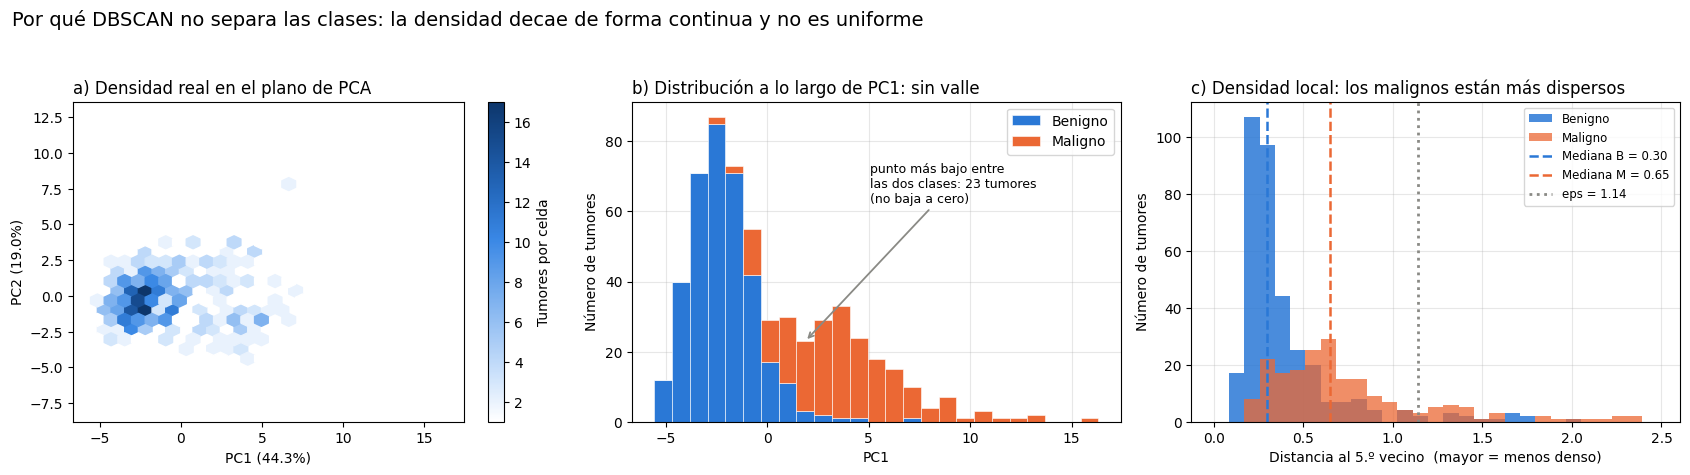

Distancia mediana al 5.º vecino — Benignos: 0.299   Malignos: 0.653
Los tumores malignos están 2.18 veces más dispersos que los benignos.

Conteo de tumores a lo largo de PC1 (de izquierda a derecha):
  PC1 [ -5.57,  -4.00)  ██████████████                             42
  PC1 [ -4.00,  -2.44)  ███████████████████████████████████████████ 131
  PC1 [ -2.44,  -0.88)  ██████████████████████████████████████████ 127
  PC1 [ -0.88,   0.69)  ███████████████████████                    71
  PC1 [  0.69,   2.25)  ████████████████                           48
  PC1 [  2.25,   3.81)  ███████████████████                        59
  PC1 [  3.81,   5.38)  ██████████████                             42
  PC1 [  5.38,   6.94)  ██████                                     19
  PC1 [  6.94,   8.50)  ████                                       14
  PC1 [  8.50,  10.07)  ██                                         8
  PC1 [ 10.07,  11.63)  █                                          3
  PC1 [ 11.63,  13.19)  █   

In [32]:
# ¿Por qué DBSCAN no separa las clases? Porque la densidad de los datos
# ni cae a cero entre las clases, ni es uniforme dentro de ellas.
from matplotlib.colors import LinearSegmentedColormap

RAMPA_AZUL = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
mapa_densidad = LinearSegmentedColormap.from_list("azules", RAMPA_AZUL)

pc1 = X_pca[:, 0]
dist_5 = distancias[:, -1]          # distancia al 5.º vecino, calculada antes
med_b, med_m = np.median(dist_5[(y == "B").values]), np.median(dist_5[(y == "M").values])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# a) Mapa de densidad en el plano de PCA
hb = axes[0].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=26, cmap=mapa_densidad, mincnt=1)
fig.colorbar(hb, ax=axes[0], label="Tumores por celda")
axes[0].set_title("a) Densidad real en el plano de PCA", loc="left")
axes[0].set_xlabel(f"PC1 ({var[0]:.1%})"); axes[0].set_ylabel(f"PC2 ({var[1]:.1%})")

# b) Distribución a lo largo de PC1: ¿hay un valle entre las clases?
bordes = np.linspace(pc1.min(), pc1.max(), 26)
# Apiladas: el contorno superior es el total, que es lo que "ve" DBSCAN
axes[1].hist([pc1[(y == "B").values], pc1[(y == "M").values]], bins=bordes, stacked=True,
             color=[AZUL, NARANJA], label=["Benigno", "Maligno"],
             edgecolor="white", linewidth=0.4)
conteo_tot, _ = np.histogram(pc1, bins=bordes)
centros = (bordes[:-1] + bordes[1:]) / 2
i_valle = int(np.argmin(conteo_tot[4:12])) + 4          # mínimo en la zona de contacto
axes[1].annotate(f"punto más bajo entre\nlas dos clases: {conteo_tot[i_valle]} tumores\n(no baja a cero)",
                 xy=(centros[i_valle], conteo_tot[i_valle]),
                 xytext=(centros[i_valle] + 3.2, conteo_tot.max() * 0.72),
                 fontsize=9, ha="left",
                 arrowprops=dict(arrowstyle="->", color=GRIS, lw=1.3))
axes[1].set_title("b) Distribución a lo largo de PC1: sin valle", loc="left")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("Número de tumores")
axes[1].legend()

# c) Densidad local por clase: distancia al 5.º vecino
bordes_d = np.linspace(0, np.percentile(dist_5, 98), 30)
axes[2].hist(dist_5[(y == "B").values], bins=bordes_d, color=AZUL, alpha=0.85, label="Benigno")
axes[2].hist(dist_5[(y == "M").values], bins=bordes_d, color=NARANJA, alpha=0.75, label="Maligno")
axes[2].axvline(med_b, color=AZUL, ls="--", lw=1.8, label=f"Mediana B = {med_b:.2f}")
axes[2].axvline(med_m, color=NARANJA, ls="--", lw=1.8, label=f"Mediana M = {med_m:.2f}")
axes[2].axvline(EPS, color=GRIS, ls=":", lw=2, label=f"eps = {EPS}")
axes[2].set_title("c) Densidad local: los malignos están más dispersos", loc="left")
axes[2].set_xlabel("Distancia al 5.º vecino  (mayor = menos denso)")
axes[2].set_ylabel("Número de tumores")
axes[2].legend(fontsize=8.5)

for ax in axes[1:]:
    ax.grid(alpha=0.3); ax.set_axisbelow(True)
fig.suptitle("Por qué DBSCAN no separa las clases: la densidad decae de forma continua y no es uniforme",
             x=0.01, ha="left", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

print(f"Distancia mediana al 5.º vecino — Benignos: {med_b:.3f}   Malignos: {med_m:.3f}")
print(f"Los tumores malignos están {med_m / med_b:.2f} veces más dispersos que los benignos.\n")
print("Conteo de tumores a lo largo de PC1 (de izquierda a derecha):")
conteo, bb = np.histogram(pc1, bins=14)
for c, (a, b) in zip(conteo, zip(bb[:-1], bb[1:])):
    print(f"  PC1 [{a:6.2f}, {b:6.2f})  {'█' * int(c / 3):<42} {c}")

**a) Densidad en el plano de PCA.** El mapa muestra un núcleo muy denso a la izquierda (los tumores benignos) del que sale una cola cada vez más dispersa hacia la derecha (los malignos). No hay dos núcleos densos separados: hay uno solo que se va deshilachando.

**b) Distribución a lo largo de PC1.** Esta es la prueba de que **no existe un valle de densidad**. Para que DBSCAN separe dos grupos tiene que haber entre ellos una franja casi vacía. Aquí el punto más bajo de la zona de contacto todavía tiene 23 tumores, así que la cadena de vecinos nunca se interrumpe y el algoritmo recorre toda la nube como si fuera un solo grupo.

**c) Densidad local por clase.** Esta es la segunda razón, y es la limitación clásica de DBSCAN: **la densidad no es uniforme**. La distancia mediana al 5.º vecino es de 0.30 en los benignos y 0.65 en los malignos, es decir que los malignos están **2.18 veces más dispersos**. Como DBSCAN usa un solo `eps` global, no puede ajustarse a las dos regiones al mismo tiempo:

- Un `eps` del tamaño de la densidad benigna (≈ 0.30) deja a casi toda la región maligna fuera, como ruido.
- Un `eps` del tamaño de la densidad maligna (≈ 0.65 o más) es tan grande para la zona benigna que fusiona todo en un solo grupo.

El `eps = 1.14` del codo está por encima de las dos medianas, así que cae del lado de la segunda opción: un grupo único con un 7.4 % de ruido. La gráfica de sensibilidad del punto 4.3 confirma que no hay ningún valor intermedio que resuelva el conflicto.

**Conclusión metodológica.** Los parámetros se escogieron con el procedimiento correcto, y lo que el procedimiento revela es que la distribución de este dataset no cumple el supuesto de DBSCAN: las clases forman un continuo de densidad decreciente, no dos regiones densas separadas por un vacío. Para distribuciones con densidad variable como esta, la respuesta metodológica serían algoritmos como **HDBSCAN** u **OPTICS**, que en lugar de un `eps` único exploran varios niveles de densidad a la vez.

## 5. Gráficos de resultados

Los tres gráficos usan el mismo plano (las 2 componentes de PCA), así que son directamente comparables:

- **a) Original:** cada punto coloreado según su diagnóstico real.
- **b) K-Means:** coloreado según el cluster asignado, con los centroides marcados.
- **c) DBSCAN:** coloreado según el cluster, con el ruido en gris y marcado con ×.

*Nota: las etiquetas de cluster (0 y 1) son arbitrarias, porque el algoritmo no sabe cuál grupo es cuál. Se renombraron según la clase mayoritaria de cada grupo, únicamente para que los colores de (a) y (b) sean comparables a simple vista.*

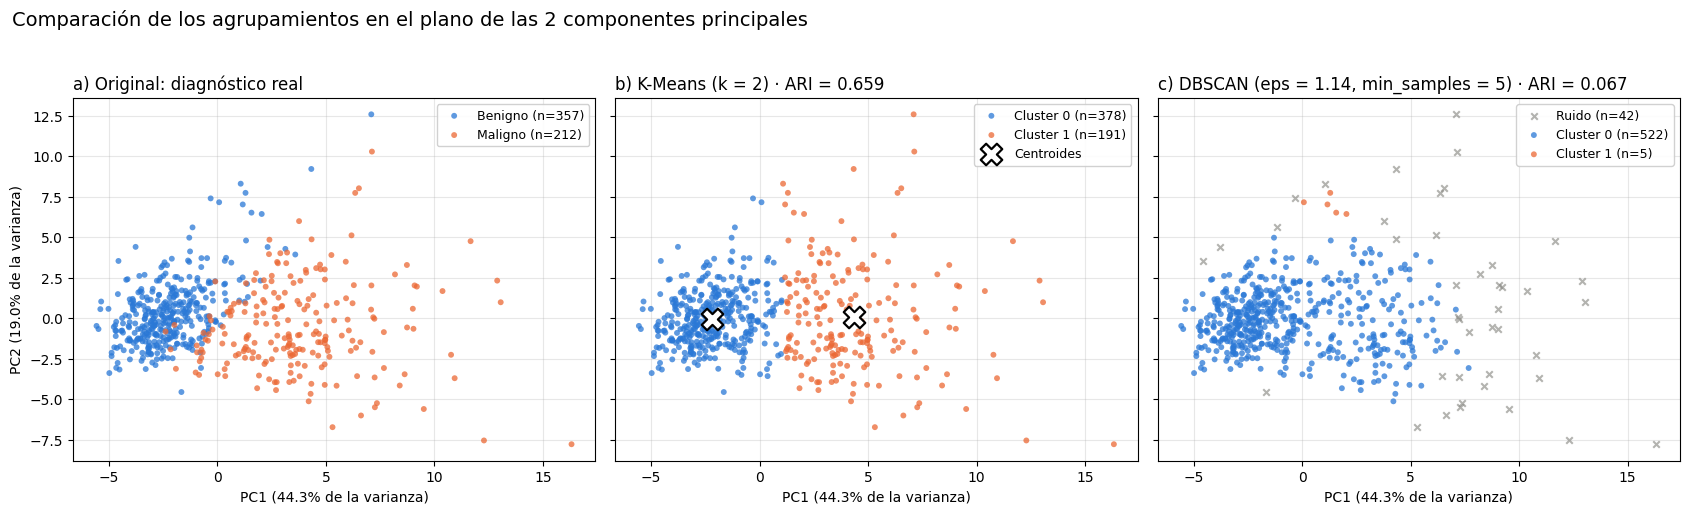

In [33]:
PALETA = {0: AZUL, 1: NARANJA, 2: VERDE, 3: AMARILLO}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)

# a) Original: el diagnóstico real
for cl, nombre in [("B", "Benigno"), ("M", "Maligno")]:
    m = (y == cl).values
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.75, edgecolors="none",
                    c=(AZUL if cl == "B" else NARANJA), label=f"{nombre} (n={m.sum()})")
axes[0].set_title("a) Original: diagnóstico real", loc="left")

# b) K-Means
for c in sorted(set(etq_km)):
    m = etq_km == c
    axes[1].scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.75, edgecolors="none",
                    c=PALETA[c], label=f"Cluster {c} (n={m.sum()})")
axes[1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                s=240, marker="X", c="white", edgecolors="black", linewidths=1.6,
                zorder=5, label="Centroides")
axes[1].set_title(f"b) K-Means (k = 2) · ARI = {ari_km:.3f}", loc="left")

# c) DBSCAN
for c in sorted(set(etq_db)):
    m = etq_db == c
    if c == -1:
        axes[2].scatter(X_pca[m, 0], X_pca[m, 1], s=22, alpha=0.65, marker="x",
                        c=GRIS, label=f"Ruido (n={m.sum()})")
    else:
        axes[2].scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.75, edgecolors="none",
                        c=PALETA[c % 4], label=f"Cluster {c} (n={m.sum()})")
axes[2].set_title(f"c) DBSCAN (eps = {EPS}, min_samples = {MIN_SAMPLES}) · ARI = {ari_db:.3f}", loc="left")

for ax in axes:
    ax.set_xlabel(f"PC1 ({var[0]:.1%} de la varianza)")
    ax.grid(alpha=0.3); ax.set_axisbelow(True)
    ax.legend(loc="upper right", fontsize=9, framealpha=0.9)
axes[0].set_ylabel(f"PC2 ({var[1]:.1%} de la varianza)")
fig.suptitle("Comparación de los agrupamientos en el plano de las 2 componentes principales",
             x=0.01, ha="left", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

In [34]:
comparacion = pd.DataFrame({
    "K-Means (k=2)": {
        "Grupos encontrados": 2,
        "Puntos sin asignar": 0,
        "Silueta": round(sil_km, 4),
        "ARI vs diagnóstico": round(ari_km, 4),
        "NMI vs diagnóstico": round(nmi_km, 4),
    },
    f"DBSCAN (eps={EPS}, ms={MIN_SAMPLES})": {
        "Grupos encontrados": n_clusters_db,
        "Puntos sin asignar": int(es_ruido.sum()),
        "Silueta": round(sil_db, 4) if sil_db == sil_db else None,
        "ARI vs diagnóstico": round(ari_db, 4),
        "NMI vs diagnóstico": round(nmi_db, 4),
    },
}).T

print("Comparación de los dos algoritmos de agrupamiento:\n")
comparacion

Comparación de los dos algoritmos de agrupamiento:



,Grupos encontrados,Puntos sin asignar,Silueta,ARI vs diagnóstico,NMI vs diagnóstico
K-Means (k=2),2.0,0.0,0.5085,0.6592,0.5404
"DBSCAN (eps=1.14, ms=5)",2.0,42.0,0.4316,0.0671,0.0733


### Conclusiones de la tercera etapa

- **Escalado:** indispensable antes de PCA y de cualquier algoritmo basado en distancias. Sin él, `area_mean` habría dominado todo el análisis por su magnitud.
- **PCA:** 2 componentes conservan el 63 % de la varianza y permiten visualizar los 569 tumores en un plano. PC1 resume el tamaño y la irregularidad del contorno, que son justamente las variables más correlacionadas con la malignidad según la etapa 1.
- **K-Means (k = 2):** agrupa con una concordancia del 90.7 % respecto al diagnóstico real (ARI = 0.659) **sin haber visto las etiquetas**. Esto confirma que la diferencia entre tumores benignos y malignos es una estructura real de los datos y no un artefacto del etiquetado.
- **DBSCAN:** no logra separar las clases (ARI = 0.067) porque entre ambas no hay una región de baja densidad. En cambio, identifica como ruido a 42 tumores de los que el 81 % son malignos, funcionando como detector de casos extremos.
- **Comparación con la etapa 2:** el mejor clasificador supervisado alcanzó 97.4 % de exactitud frente al 90.7 % de concordancia de K-Means. La brecha mide el valor de las etiquetas: el agrupamiento descubre la estructura general, pero necesita supervisión para afinar la frontera entre las dos clases, que es precisamente donde está el riesgo clínico.